# Bắt đầu Phase 04.1 - Tìm hiểu dữ liệu:
### Chúng ta có ba bộ dữ liệu UNSW-NB15, CIC-IDS2017 và CTU-13.
- Bài toán trước mắt: Làm thế nào để biết dữ liệu có phù hợp cho việc huấn luyện mô hình phát hiện xâm nhập hay không?
- Trước khi trả lời, chúng ta cần xác định d liệu có phù hợp cho việc huấn luyện mô hình phát hiện xâm nhập hay không?
- Mình chọn UNSW-NB15 Training làm bộ dữ liệu đầu tiên vì nó đã có phân chia training và testing và có cả nhãn nhị phân "lable" lẫn nhãn loại tấn công "attack_cat".
- Ta sẽ làm trong Notebook đã có sẵn: "D:\suricata-ai-project\notebooks\01_unsw_eda.ipynb".

- Trước hết ta dùng pandas.
- Tại sao chọn pandas? Vì nó cung cấp cấu trúc DataFrame, giúp thao tác và phân tích dữ liệu dạng bảng thianaj tiện hơn so với việc tự xử lý từng dòng bằng thư viện csv.

In [195]:
from pathlib import Path # Giúp làm việc với đường dẫn theo cách rõ ràng, không cần nối chuỗi đường dẫn thủ công.

# print("Working directory:", Path.cwd()) # Cho biết thư mục đang làm việc  hiện tại của python

root = Path.cwd() # lấy thư mục làm việc của Notebook.

if root.name == "notebooks":
    root = root.parent  # Nếu đang đứng trong notebooks/, .parent đưa chúng ta về thư mục gốc dự án.

data_path = root / "data" / "raw" / "unsw-nb15" / "UNSW_NB15_training-set.csv"  # Toán tử / trong pathlib dùng để ghép đường dẫn.

print("Dataset:", data_path)
print("File exists:", data_path.is_file()) # is_file() kiểm tra file có tồn tại hay không.

Dataset: D:\suricata-ai-project\data\raw\unsw-nb15\UNSW_NB15_training-set.csv
File exists: True


In [196]:
import pandas as pd

df = pd.read_csv(data_path, nrows=5) # Khảo sát 5 dòng dữ liệu nhỏ đầu tiên.
# df là một Pandas DataFrame: Cấu trúc dữ liệu dạng bảng, gồm các cột.
# dur, proto và sbytes có thể là các đặc trưng đầu vào, label là nhãn mục tiêu.

display(df)

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [197]:
print("Shape:", df.shape) # Dataset hiện có bao nhiêu hàng, bao nhiêu cột?
print("Columns:", df.columns.tolist()) # Tên của các đặc trưng là gì?
print("Data types:")
print(df.dtypes) # Mỗi đặc trưng đang lưu dưới kiểu dữ liệu nào?

Shape: (5, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']
Data types:
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss       

### Trong UNSW-NB15, có hai cột rất quan trọng:
- label: nhãn nhị phân, dùng để phân biệt lưu lượng bình thường và tấn công (0: Normal, 1: Attack).
- attack_cat: mô tả loại tấn công.

In [198]:
display(df[["proto","service","dur","attack_cat","label"]])

,proto,service,dur,attack_cat,label
0,tcp,-,0.121478,Normal,0
1,tcp,-,0.649902,Normal,0
2,tcp,-,1.623129,Normal,0
3,tcp,ftp,1.681642,Normal,0
4,tcp,-,0.449454,Normal,0


### Bài toán: UNSW-NB15 chứa dữ liệu mạng bình thường và các cuộc tấn công. Trước khi huấn luyện mô hình, làm sao biết dữ liệu có đủ tin cậy để sử dụng?
#### Ta sẽ giải quyết ba câu hỏi:
1. Dataset thực tế có bao nhiêu bản ghi?
2. Có giá trị bị thiếu không, và thiếu ở cột nào?
3. Dữ liệu bình thường và tấn công có cân bằng không?

In [199]:
train_df=pd.read_csv(data_path) # đọc toàn bộ file CSV, không còn giới hạn nrows.
# DataFrame chứa dữ liệu training. Đặt tên rõ ràng để sau này phân biệt với test_df.
print("Số bản ghi:", train_df.shape[0]) # shape[0]: Số hàng.
print("Số cột: ", train_df.shape[1]) # shape[1]: Số cột.

Số bản ghi: 175341
Số cột:  45


- Nếu chỉ phân tích 5 dòng, ta không thể ddassnh giá mực độ thếu dữ liệu hay phân bố nhãn trên toàn tập.
- Dataset UNSW-NB15 Training có kích thước khoản 30.8mb vieejcc đọc vào ram thường phù hợp với máy tính cá nhân.

#### Missing Value: Những giá trị bị thiếu trong bảng dữ liệu, thường được Pandas biểu diễu bằng NaN hoặc pd.NA.
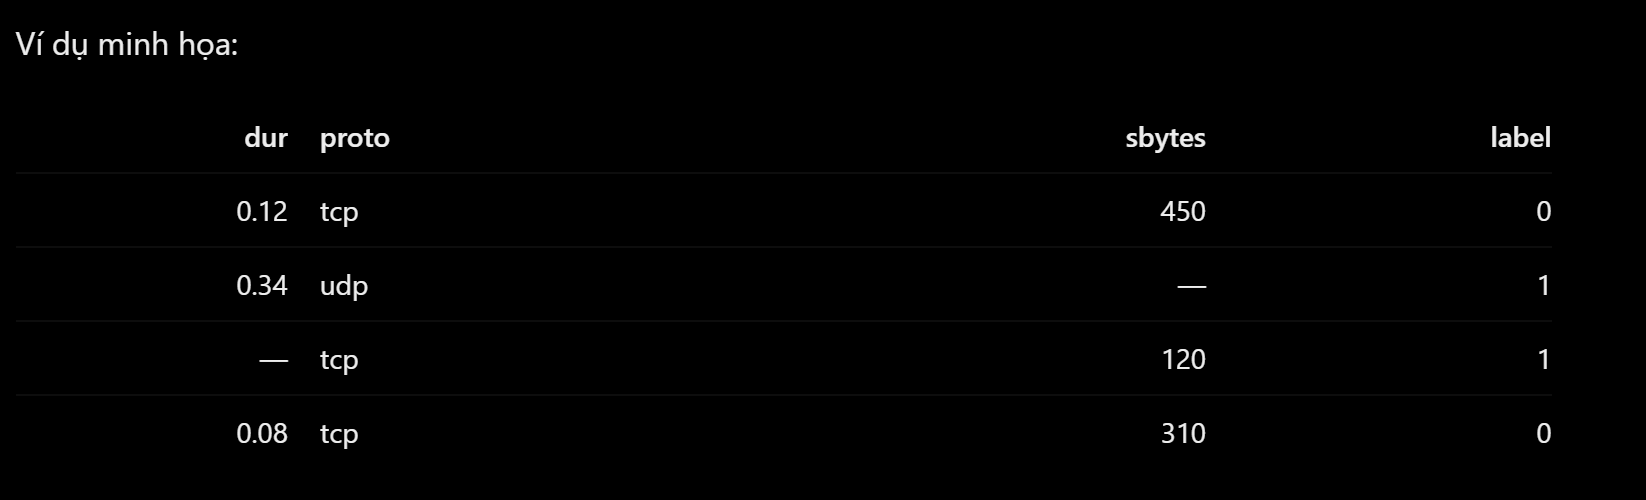
- Trong bảng này, cột sbytes và dur có ột giá trị thiếu.
- Đó là điều khá nguy hiểm, nhiều thuật toán không xử lý trực tiếp các giá trị thiếu, và cách thay thế không phù hợp và có thể làm sai phân phối dữ liệu.

In [200]:
missing_count=train_df.isnull().sum() # Kiểm tra từng ô có bị thiếu hay không và kiểm tra từng ô có bị thiếu hay không.

print(missing_count[missing_count>0]) # Chỉ hiển thị các cột quan tâm và chọn những cột có ít nhâ một giá trị bị thiếu.

Series([], dtype: int64)


#### Tính tỷ lệ phần trăm thiếu: Chúng ta không chỉ quan tâm số lượng thiếu mà còn cần tỷ lệ thiếu theo từng cột.

In [201]:
missing_percent = train_df.isna().mean() * 100

display(
    missing_percent[missing_percent > 0]
    .sort_values(ascending=False)
)

Series([], dtype: float64)

#### Pandas xem kết quả isna() như các giá trị Boolean. Khi tính trung bình, True được tính là 1 và False là 0. Vì vậy, trung bình chính là tỷ lệ ô bị thiếu.
- Ta chưa sử dụng fillna() hay dropna(). Cần biết mức độ và nguyên nhân thiếu trước khi chọn cách xử lý; nếu cần học tham số điền giá trị, chỉ được fit trên tập training để tránh data leakage.

### Tiếp theo: Class Imbalance: Phân tích phân phối nhãn.
#### Đây là bước rất quan trọng đối với một hệ thống Instrusion Detection System (Hệ thống phát hiện xâm nhập).

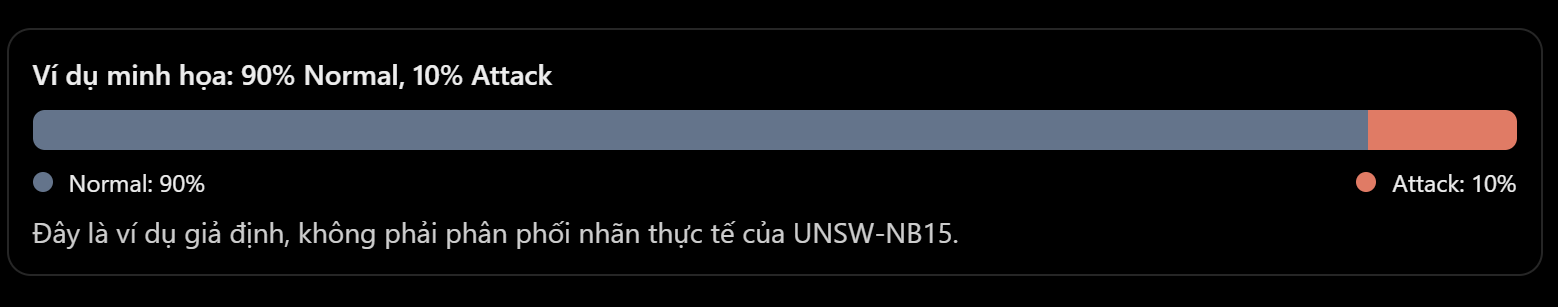

- Trong ví dụ này, một mô hình luôn dự đoán Normal sẽ đạt Accuracy 90% nhưng không phát hiện được cuộc tấn công nào.
- Vì vậy: đối với IDS, ngoài Accuracy về sau chúng ta cần đánh giá Recall, Precision, F1-score, confusion matrix và False Positive Rate.

In [202]:
label_counts=train_df["label"].value_counts(dropna=False) # Chọn cột nhãn nhị phân và đếm số lượng xuất hiện giữ cả nhãn thiếu trong thống kế nếu có, tránh vô tình bỏ qua những bản ghi có vấn đề của từng giá trị.
print(label_counts)
# 0: Normal
# 1: Attack

label
1    119341
0     56000
Name: count, dtype: int64


In [203]:
# Tính phần trăm từng lớp

"""
    - Mặc định: .value_counts(): trả về số lượng phần tử theo điều kiện trước đó.
                        => Khi thêm: normalize=True, nó trả về tỷ lệ tương đối của mỗi nhãn
                        => *100 sẽ ra được tỉ lệ phần trăm.
"""
label_percent = (
    train_df["label"].value_counts(normalize=True, dropna=False)*100
)

print(label_percent)

label
1    68.062233
0    31.937767
Name: proportion, dtype: float64


#### Kết quả hiện tại cho ta thấy:
- Data Attack > data Normal.

- Feature (X): dur, proto, sbytes, dbytes, spkts, dpkts ... là thông tin mô hình sử dụng để dự đoán.
- Label (y): label = 0 hoặc label = 1 là đáp án đúng mà mô hình học trong giai đoạn training.
- Khi triển khai thật, Suricata không cần gửi nhãn label cho mô hình. Mô hình sẽ tự dự đoán nhãn từ các feature của lưu lượng mạng.

#### UNSW-NB15  có hai loại nhãn:
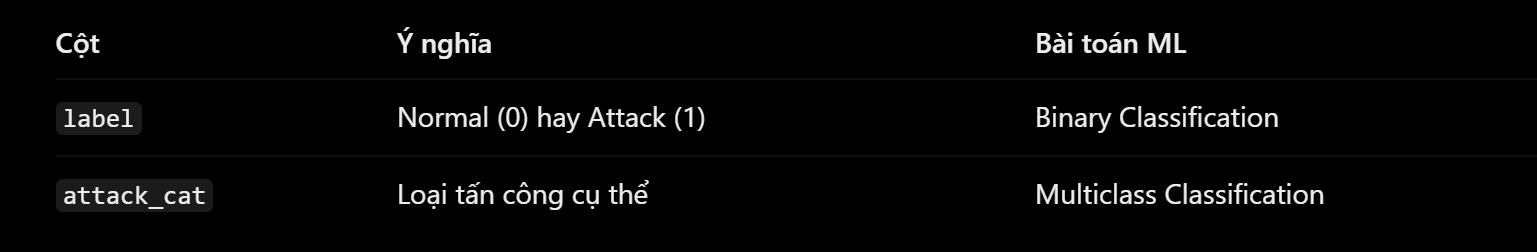

- Giả sử một bản ghi có: label = 0, attack_cat = Expoits
- Điều này có thể cho thấy nhãn không nhất quán: bản ghi được đánh dấu Normal nhưng lại mang tên cột loại tấn công.
- Nếu có những trường hợp như vậy, chúng ta cần tìm hiểu nguyên nhân trước khi huấn luyện.
- Vì: Dữ liệu gán nhãn sai có thể khiến mô hình học những quy luật mâu thuẫn.

In [204]:
# Tạo bảng, đếm số tổ hợp bản ghi theo từng tổ hợp giá trị của hai cột.
label_table = pd.crosstab(
    train_df["attack_cat"],
    train_df["label"],
    dropna=False
)

display(label_table)

label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


In [205]:
# .isin([0, 1]): Trả về true nếu giá trị là 0 hoặc 1.
# ~: đảo kết quả Boolean.
invalid_labels = ~train_df["label"].isin([0, 1])

print("Số nhãn không hợp lệ:", invalid_labels.sum()) # đếm các giá trị True

Số nhãn không hợp lệ: 0


In [206]:
# Đếm số lượng tấn công của mỗi loại.
attack_counts = train_df["attack_cat"].value_counts(dropna=False)

display(attack_counts)

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

#### Kiểm tra dữ liệu trùng lặp:

In [207]:
# .drop(columns=[...]): loại bỏ các cột chỉ định ra khỏi phép so sánh.
feature_df = train_df.drop(
    columns=["id", "label", "attack_cat"]
)
"""
    - Xóa id: vì nó định danh mỗi dòng => Khiến dữ liệu luôn khác nhau.
    - Xóa label và attack_cat: vì chúng ta muốn kiểm tra các đặc trưng đầu vào, không phải đáp án của mô hình.
"""


# .duplicated(): đánh dấu những hàng có feature giống một hàng xuất hiện trước.
duplicate_count = feature_df.duplicated().sum()

print("Số bản ghi trùng feature:", duplicate_count)
print("Tỷ lệ trùng (%):", round(
    duplicate_count / len(feature_df) * 100, 2
))

Số bản ghi trùng feature: 74301
Tỷ lệ trùng (%): 42.38


In [208]:
import numpy as np

numeric_df = train_df.select_dtypes(include="number")

# .inf(...): xác định các giá trị infinity(âm hoặc dương) trong bảng chỉ định
inf_counts = np.isinf(numeric_df).sum()

display(inf_counts[inf_counts > 0])

Series([], dtype: int64)

### Phân tích dữ liệu sau khi phân tích Quality:
- Dữ liệu Training có tổng cổng 175.341 bản ghi. thuộc 10 nhóm gồm Normal và 9 loại tấn công.

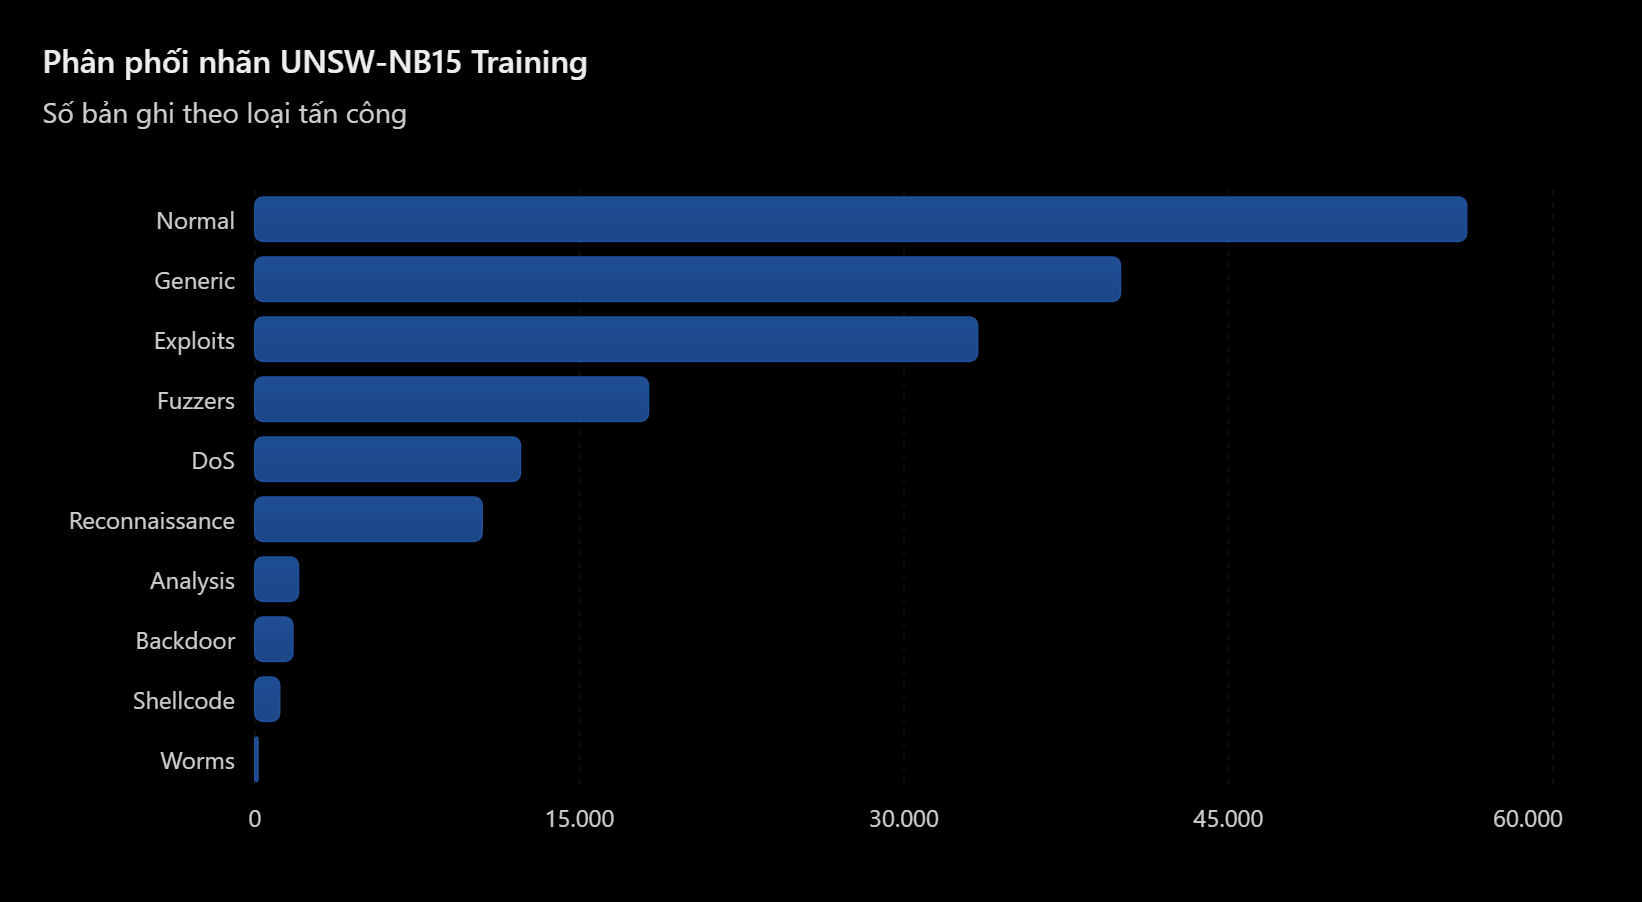

- Normal: 56.000 bản ghi — là nguồn dữ liệu ứng viên để xây dựng mô hình học hành vi bình thường.
- Reconnaissance: 10.491 bản ghi — đáng chú ý vì chúng ta đã chọn thăm dò mạng làm kịch bản nghiên cứu chính.
- DoS: 12.264 bản ghi — có thể hỗ trợ nghiên cứu mở rộng.
- Worms: chỉ 130 bản ghi — rất ít so với Generic hoặc Exploits.

- 42.38% dữ liệu trùng => 74.301 hàng trùng với 1 hàng xuất hiện trước đó.

In [209]:
full_duplicate_count = train_df.drop(
    columns=["id"]
).duplicated().sum()

print("Trùng feature:", duplicate_count)
print("Trùng feature + label:", full_duplicate_count)

Trùng feature: 74301
Trùng feature + label: 67601


- Ở phép kiểm tra trước, chúng ta loại id, label, attack_cat.
- Còn lần này chỉ loại id, tức là giữ cả nhãn để kiểm tra.
- Nếu số lượng trùng feature lớn hơn số lượng trùng cả feature + label, chúng ta có dấu hiệu rằng một số bản ghi có feature giống nhau nhưng nhãn hoặc loại tấn công khác nhau.
- Lưu ý: đó mới là dấu hiệu, chưa đủ để kết luận có nhãn nhị phân mâu thuẫn.

#### Kiểm tra feature giống nhau có nhãn nhị phân khác nhau không:

In [210]:
feature_hash = pd.util.hash_pandas_object(
    feature_df,
    index=False
)

label_groups = train_df.groupby(feature_hash)["label"].nunique()

conflicting_groups = label_groups[label_groups > 1]

print("Số nhóm feature có nhiều nhãn:", len(conflicting_groups))

Số nhóm feature có nhiều nhãn: 229


- Vì chúng ta muốn tạo một giá trị đại diện cho toàn bộ feature của mỗi bản ghi.
- Hai bản ghi có cùng giá trị trên mọi feature sẽ có cùng hash. Điều này giúp gom nhóm và kiểm tra nhãn hiệu quả hơn so với việc tự viết vòng lặp so sánh từng hàng.
- hash_pandas_object() sử dụng hash để phục vụ xử lý dữ liệu, không phải mã hóa bảo mật. Về lý thuyết vẫn có thể xảy ra hash collision, nên những nhóm bất thường cần được đối chiếu lại với feature gốc trước khi kết luận.
- nunique() đếm số giá trị nhãn khác nhau trong mỗi nhóm feature.

#### Đếm số bản ghi nằm trong các nhóm mâu thuẫn:

In [211]:
conflicting_rows = feature_hash.isin(conflicting_groups.index)

print("Số bản ghi cần điều tra:", conflicting_rows.sum())

Số bản ghi cần điều tra: 940


### Phân tích sự trùng lặp và mâu thuẫn nhãn:

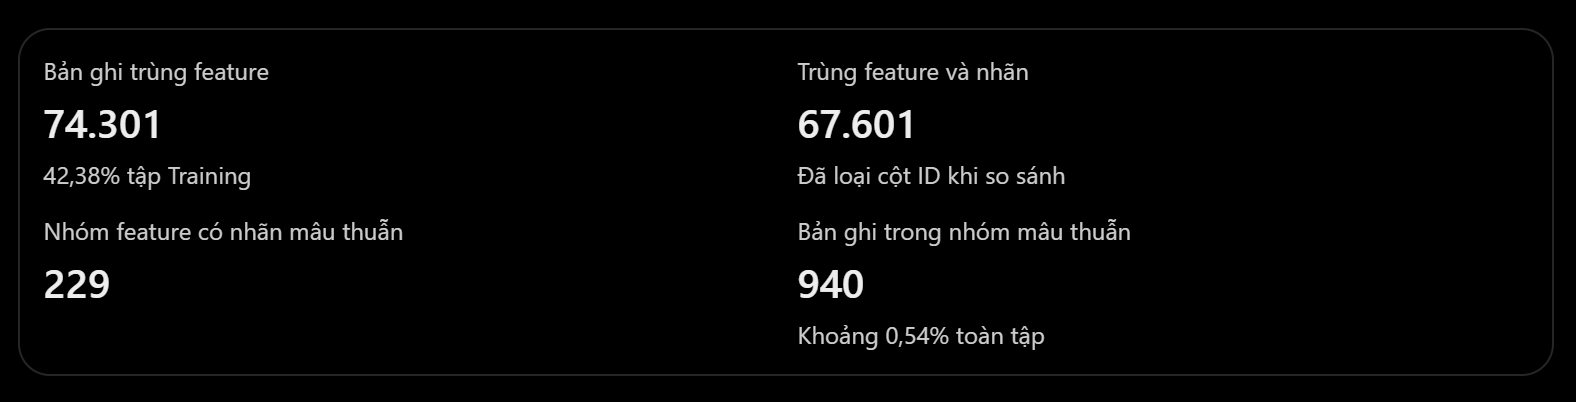

- Phân biệt hai kết quả rất dễ nhầm
- 74.301 − 67.601 = 6.700 không có nghĩa chúng ta đã tìm thấy 6.700 bản ghi gán nhãn nhị phân sai.
- Lý do: phép kiểm tra feature + label của bạn thực tế giữ cả label và attack_cat. Những bản ghi có cùng feature nhưng khác loại tấn công cũng làm thay đổi số lượng duplicate, kể cả khi nhãn nhị phân đều bằng 1.
- Kết quả cần chú ý hơn là: 229 nhóm feature có nhiều nhãn nhị phân khác nhau, chứa tổng cộng 940 bản ghi.

- Điều này có nghĩa là một số feature vector có thể tương ứng với cả Normal lẫn Attack. Đây là mâu thuẫn đối với bài toán phân loại dựa trên chính bộ feature đó, nhưng chưa chứng minh các nhãn gốc bị gán sai. Nguyên nhân cũng có thể là bộ feature không đủ thông tin để phân biệt hai tình huống.

- Giả sử hai flow có cùng tất cả feature mà mô hình được cung cấp:
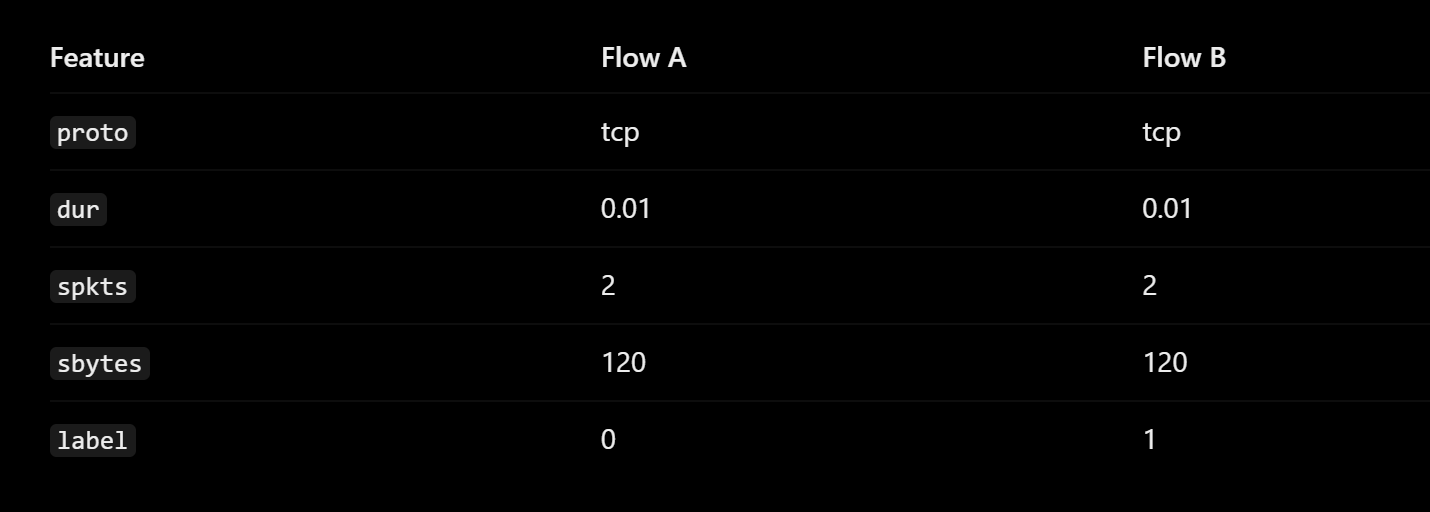

- Nếu mô hình chỉ nhận bốn feature trên, nó không có đủ thông tin để phân biệt hai bản ghi.
- Đối với Isolation Forest, vấn đề càng đặc biệt: mô hình học cấu trúc dữ liệu Normal, nhưng một flow được gán Attack có thể trông giống Normal trong không gian feature.
- Điều đó không có nghĩa Isolation Forest hoạt động sai. Nó cho thấy khả năng phát hiện phụ thuộc vào những đặc trưng mà hệ thống có thể quan sát.
- Đây cũng là lý do chúng ta đã chọn DL phân tích chuỗi hành vi theo thời gian để bổ sung ngữ cảnh cho ML mức flow.

### Phân tích Các nhóm mâu thuẫn thuộc loại tấn công nào:

In [212]:
# .loc[conflicting_rows]: lọc những bản ghi thuộc nhóm feature có nhiều nhãn.
conflict_df = train_df.loc[conflicting_rows]

print("Phân phối nhãn:")
display(conflict_df["label"].value_counts())

print("Phân phối loại tấn công:")
display(conflict_df["attack_cat"].value_counts())

Phân phối nhãn:


label
1    544
0    396
Name: count, dtype: int64

Phân phối loại tấn công:


attack_cat
Fuzzers      543
Normal       396
Shellcode      1
Name: count, dtype: int64

In [213]:
# first_hash chọn một nhóm nghi ngờ; sample_mask tìm các bản ghi thuộc nhóm đó. Bảng hiển thị cho phép quan sát sự khác biệt về nhãn.
first_hash = conflicting_groups.index[0]

sample_mask = feature_hash == first_hash

columns = [
    "id", "proto", "dur",
    "spkts", "dpkts",
    "sbytes", "dbytes",
    "attack_cat", "label"
]

display(
    train_df.loc[sample_mask, columns].head(15)
)

,id,proto,dur,spkts,dpkts,sbytes,dbytes,attack_cat,label
47563,47564,udp,0.000001,2,0,104,0,Normal,0
48339,48340,udp,0.000001,2,0,104,0,Fuzzers,1
51236,51237,udp,0.000001,2,0,104,0,Fuzzers,1
89153,89154,udp,0.000001,2,0,104,0,Fuzzers,1
98766,98767,udp,0.000001,2,0,104,0,Fuzzers,1


In [214]:
candidate_features = feature_df.loc[sample_mask]

print(
    "Số feature vector phân biệt:",
    len(candidate_features.drop_duplicates())
)

Số feature vector phân biệt: 1


### Phân tích kết quả phía trên:
- Cùng một bộ đặc trưng đầu vào nhưng lịa có thể mang hai nhãn Normal và Attack khác nhau.
- Điều này xác nhận trong nhóm ví dụ, toàn bộ các feature được so sánh đều giống nhau, không chỉ sáu cột đang hiển thị trong ảnh.
    - Giả sử hai bản ghi có cùng toàn bộ feature nhưng nhãn khác nhau.
    - Một mô hình phân loại xác định, khi nhận cùng input, sẽ tạo cùng kết quả dự đoán. Nó không thể nhận ra bản ghi nào là Normal, bản ghi nào là Fuzzers nếu không có thêm thông tin phân biệt.
    - Đây là biểu hiện của hiện tượng feature ambiguity — thông tin đầu vào chưa đủ để xác định duy nhất nhãn.
    - Không thể kết luận ngay dataset bị gán nhãn sai. Có thể hai hoạt động mạng thực sự khác nhau nhưng trở nên giống nhau sau khi được biểu diễn bằng bộ feature hiện tại.
----
- Đây là ví dụ rất phù hợp để giải thích sự phân chia nhiệm vụ mà ta đã thống nhất:
    - Machine Learning — Phân tích flow
        - Nếu hai flow có toàn bộ feature giống nhau, ML không có căn cứ để phân biệt chúng bằng những feature đó.
    - Deep Learning — Phân tích chuỗi hành vi
        - Nếu có dữ liệu thời gian và liên kết các flow, DL có thể nghiên cứu ngữ cảnh trước/sau để tìm những mẫu hành vi khác nhau.

### Kiểm tra Data Leakage giữa Training và Testing

Bài toán
UNSW-NB15 đã cung cấp hai file:
- UNSW_NB15_training-set.csv
- UNSW_NB15_testing-set.csv
Nhưng liệu một feature vector trong tập Training có xuất hiện lại trong tập Testing không?

Nếu có, kết quả đánh giá mô hình có thể trở nên lạc quan hơn, đặc biệt với những phương pháp nhạy cảm với các mẫu lặp.

Ta sẽ kiểm tra, không thay đổi cách chia tập chính thức ở thời điểm này.

In [215]:
# with_name() thay tên file trong cùng thư mục. Nhờ đó, chúng ta không cần viết lại toàn bộ đường dẫn.
test_path = data_path.with_name("UNSW_NB15_testing-set.csv")

test_df = pd.read_csv(test_path)

print("Training:", train_df.shape)
print("Testing:", test_df.shape)

Training: (175341, 45)
Testing: (82332, 45)


In [216]:
# Kiểm tra tính tương thích của cột
"""
    - Hai tập dữ liệu phải sử dụng cùng định nghĩa và thứ tự feature trước khi chúng ta so sánh.
    - Nếu danh sách cột không giống nhau, việc tạo hash có thể không còn ý nghĩa.
"""

excluded_cols = ["id", "label", "attack_cat"]

train_features = train_df.drop(columns=excluded_cols)
test_features = test_df.drop(columns=excluded_cols)

print("Số feature Training:", train_features.shape[1])
print("Số feature Testing:", test_features.shape[1])

print(
    "Cột có giống nhau không?",
    train_features.columns.equals(test_features.columns)
)

Số feature Training: 42
Số feature Testing: 42
Cột có giống nhau không? True


In [217]:
"""
    - hash_pandas_object(): tạo giá trị đại diện cho feature vector của mỗi hàng.
    - index=False: loại chỉ số hàng khỏi phép hash, vì chỉ số Training và Testing khác nhau.
    - test_hash.isin(train_hash): kiểm tra feature vector của mỗi bản ghi Testing có hash xuất hiện trong Training không.
    - .sum(): đếm số bản ghi Testing có dấu hiệu trùng.
    - Phép chia cuối cùng tính tỷ lệ trên toàn bộ Testing.
"""

train_hash = pd.util.hash_pandas_object(
    train_features, index=False
)

test_hash = pd.util.hash_pandas_object(
    test_features, index=False
)

overlap_mask = test_hash.isin(train_hash)

overlap_count = overlap_mask.sum()

print("Testing có feature trùng Training:", overlap_count)

print(
    "Tỷ lệ trùng (%):",
    round(overlap_count / len(test_df) * 100, 2)
)

Testing có feature trùng Training: 8541
Tỷ lệ trùng (%): 10.37


### Phân tích trùng lặp giữa Training và Testing
- Training và Testing có cùng 42 cột feature và cùng thứ tự cột.
- Có 8.541 bản ghi Testing có hash feature xuất hiện trong Training.
- Còn 73.791 bản ghi không có hash trùng theo phép kiểm tra này.
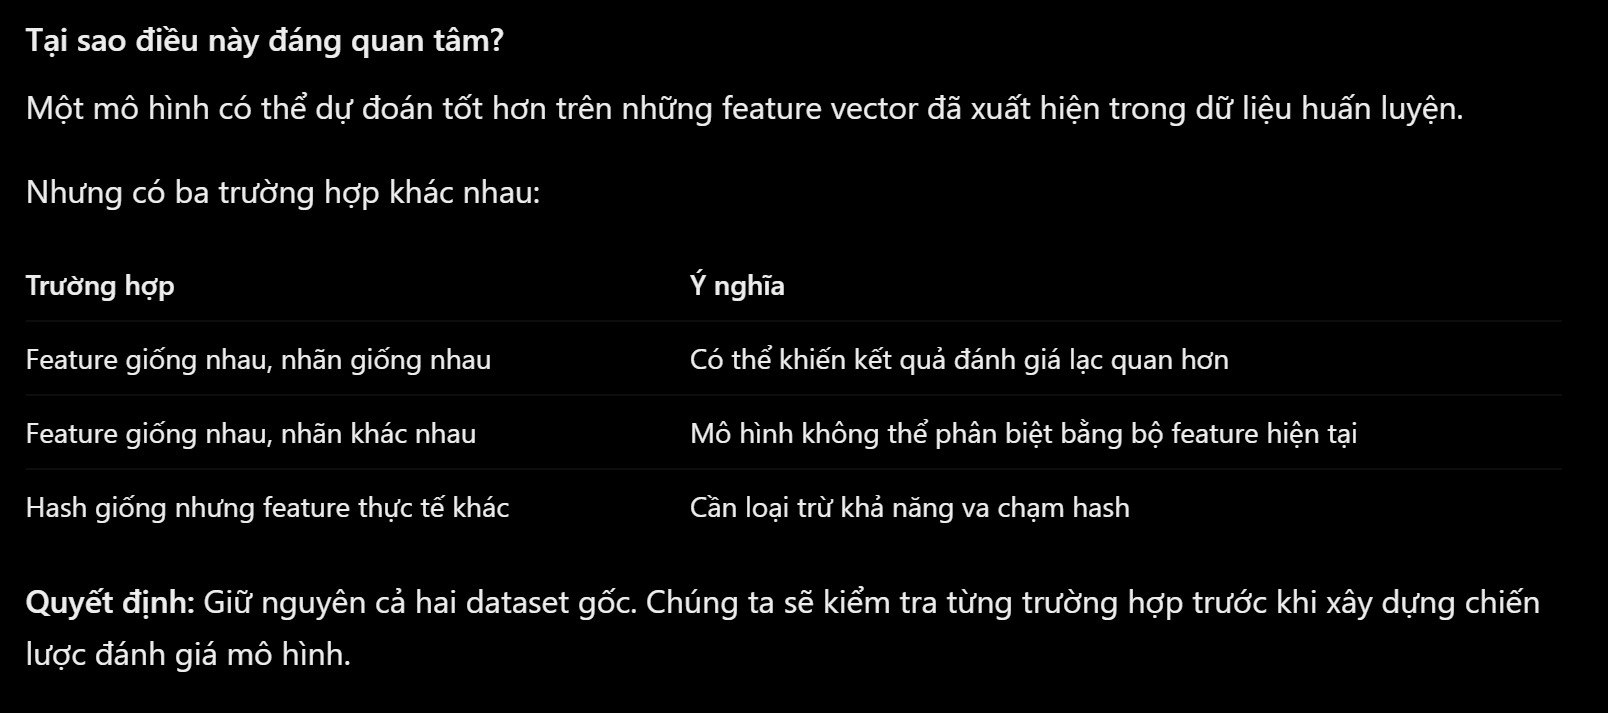

In [218]:
overlap_by_label = pd.crosstab( # đếm số mẫu theo hai điều kiện.
    test_df["label"],
    overlap_mask, # kết quả kiểm tra hash có xuất hiện trong Training hay không.
    rownames=["Label"],
    colnames=["Có hash trùng Training"]
)

display(overlap_by_label)

Có hash trùng Training,False,True
Label,,
0,35528,1472
1,38263,7069


In [219]:
"""
    - min=0, max=0: nhóm Training chỉ chứa Normal.

    - min=1, max=1: nhóm Training chỉ chứa Attack.

    - min=0, max=1: nhóm Training có cả hai nhãn.
"""

train_label_summary = (
    pd.DataFrame({
        "hash": train_hash,
        "label": train_df["label"]
    })
    .groupby("hash")["label"]
    .agg(["min", "max"])
)

In [220]:
"""
    - loc[overlap_mask]: chỉ lấy 8.541 bản ghi đang cần điều tra.
    - .map(): tra cứu thông tin nhãn của nhóm Training theo hash.
    - .to_numpy(): gán kết quả theo đúng thứ tự hàng, không phụ thuộc căn chỉnh chỉ số Pandas.
"""

overlap_df = test_df.loc[overlap_mask, ["label"]].copy()

overlap_df["train_min"] = (
    test_hash.loc[overlap_mask]
    .map(train_label_summary["min"])
    .to_numpy()
)

overlap_df["train_max"] = (
    test_hash.loc[overlap_mask]
    .map(train_label_summary["max"])
    .to_numpy()
)

In [221]:
same_label = (
    (overlap_df["train_min"] == overlap_df["train_max"])
    & (overlap_df["label"] == overlap_df["train_min"])
)

mixed_label = (
    overlap_df["train_min"] != overlap_df["train_max"]
)

different_label = (
    (overlap_df["train_min"] == overlap_df["train_max"])
    & (overlap_df["label"] != overlap_df["train_min"])
)

print("Trùng hash, cùng nhãn:", same_label.sum())
print("Trùng hash, Training có cả 2 nhãn:", mixed_label.sum())
print("Trùng hash, khác nhãn:", different_label.sum())

print("Tổng kiểm tra:", (
    same_label.sum()
    + mixed_label.sum()
    + different_label.sum()
))

Trùng hash, cùng nhãn: 8017
Trùng hash, Training có cả 2 nhãn: 228
Trùng hash, khác nhãn: 296
Tổng kiểm tra: 8541


### Phân tích từ kết quả trên:
- 8.017 bản ghi cùng nhãn: Feature hash xuất hiện trong Training, nhóm Training chỉ có một nhãn và nhãn này giống Testing. Những mẫu này có thể khiến đánh giá quá lạc quan, nhưng chưa chứng minh mô hình sẽ ghi nhớ hoặc dự đoán đúng chúng.
- 228 bản ghi thuộc nhóm nhãn hỗn hợp: Cùng một hash trong Training gắn với cả Normal và Attack. Đây là những trường hợp có tính mơ hồ cao.
- 296 bản ghi khác nhãn: Training chỉ có một nhãn cho hash đó, nhưng Testing lại mang nhãn ngược lại. Nếu feature thực sự giống hệt nhau, một mô hình chỉ quan sát bộ feature hiện tại không thể phân biệt hai trường hợp bằng thông tin đầu vào.
- Kết luận tạm thời: Có nguy cơ evaluation contamination do trùng mẫu, nhưng chúng ta cần xác minh các feature gốc trước khi đưa ra kết luận cuối cùng về mức độ ảnh hưởng.

#### Tại sao chưa xóa những bản ghi trùng?
Đây là quyết định kỹ thuật rất quan trọng.

Nếu xóa toàn bộ mẫu trùng trong Training hoặc Testing, phân phối dữ liệu có thể thay đổi, khiến thí nghiệm không còn tương đương với tập kiểm thử chính thức UNSW-NB15.

Vì vậy, mình đề xuất chiến lược đánh giá sau này:
- Baseline: Đánh giá trên tập Testing gốc để có kết quả đối chiếu.
- Overlap-aware evaluation: Báo cáo kết quả riêng cho các bản ghi có feature trùng và không trùng Training.
- Unseen-attack evaluation: Thiết kế thí nghiệm giữ riêng những nhóm hoặc biến thể tấn công chưa được đưa vào quá trình huấn luyện.
Nhưng chúng ta phải chốt quy trình trước khi fit mô hình, tránh dùng thông tin Testing để chọn tham số nhằm làm đẹp kết quả.

Đặc biệt, với Isolation Forest, nếu mô hình học Normal mà một Attack có bộ feature giống Normal, việc dự đoán sai trường hợp đó là giới hạn thông tin đầu vào, không nhất thiết là lỗi thuật toán.

### Kiểm chứng bằng dữ liệu gốc

In [222]:
candidate_test = test_features.loc[overlap_mask]

candidate_train = train_features.loc[
    train_hash.isin(test_hash.loc[overlap_mask])
].drop_duplicates()

print("Testing candidates:", len(candidate_test))
print("Unique Training candidates:", len(candidate_train))

Testing candidates: 8541
Unique Training candidates: 1302


In [223]:
exact_check = candidate_test.merge(
    candidate_train,
    on=list(train_features.columns),
    how="left",
    indicator=True,
    validate="many_to_one"
)

display(exact_check["_merge"].value_counts())

_merge
both          8541
left_only        0
right_only       0
Name: count, dtype: int64

In [224]:
exact_count = (exact_check["_merge"] == "both").sum()
hash_only_count = (exact_check["_merge"] == "left_only").sum()

print("Trùng feature thực tế:", exact_count)
print("Chỉ trùng hash:", hash_only_count)
print("Tổng ứng viên:", len(candidate_test))

Trùng feature thực tế: 8541
Chỉ trùng hash: 0
Tổng ứng viên: 8541


### Phân tích kết quả từ mô hình trên:
- Nếu mô hình được đánh giá trên Testing gốc, một phần dữ liệu kiểm thử đã có các feature vector xuất hiện trong Training. Điều đó tạo nguy cơ kết quả đánh giá lạc quan, nhưng chưa thể kết luận mức độ ảnh hưởng nếu chưa thực sự huấn luyện và so sánh các nhóm mẫu.
----
Quyết định kỹ thuật
Chúng ta sẽ:
- Giữ nguyên tập Training và Testing chính thức để phục vụ baseline.
- Khi đánh giá ML, báo cáo kết quả riêng trên nhóm Testing trùng và không trùng feature với Training.
- Với mục tiêu phát hiện tấn công mới, thiết kế thêm thí nghiệm giữ riêng nhóm tấn công chưa thấy trong quá trình huấn luyện và lựa chọn mô hình.
Chưa xóa dữ liệu trùng. Loại bỏ chúng ngay bây giờ có thể làm thay đổi phân phối dữ liệu trước khi chúng ta đánh giá được tác động.

### Feature Mapping với Suricata

In [225]:
import json

sample_path = (
    root / "data" / "samples"
    / "suricata" / "suricata-flow-sample.json"
)

raw_text = sample_path.read_text(
    encoding="utf-8-sig"
).lstrip()

event, _ = json.JSONDecoder().raw_decode(raw_text)

print("Event type:", event.get("event_type"))
print("Các trường chính:")
print(sorted(event.keys()))

Event type: flow
Các trường chính:
['event_type', 'flow', 'flow_id', 'icmp_code', 'icmp_type', 'in_iface', 'ip_v', 'proto', 'timestamp']


- json giúp Python đọc cấu trúc dữ liệu JSON.
- sample_path chỉ đến file sự kiện thực tế đã sao lưu từ VM1.
- JSONDecoder().raw_decode() đọc đối tượng JSON đầu tiên. Cách này phù hợp để khảo sát cả file chứa một JSON và file JSON Lines chứa nhiều sự kiện.
- event.get("event_type") xác định loại sự kiện Suricata.
- event.keys() cho biết những thông tin Suricata cung cấp.

In [226]:
flow = event.get("flow", {})

print("Các trường trong flow:")
print(sorted(flow.keys()))

print("\nKiểu dữ liệu:")
for field, value in flow.items():
    print(field, ":", type(value).__name__)

Các trường trong flow:
['age', 'alerted', 'bytes_toclient', 'bytes_toserver', 'end', 'pkts_toclient', 'pkts_toserver', 'reason', 'start', 'state']

Kiểu dữ liệu:
pkts_toserver : int
pkts_toclient : int
bytes_toserver : int
bytes_toclient : int
start : str
end : str
age : int
state : str
reason : str
alerted : bool


### Khảo sát feature ứng viên

In [227]:
candidate_fields = {
    "proto": event.get("proto"),
    "age": flow.get("age"),
    "pkts_toserver": flow.get("pkts_toserver"),
    "pkts_toclient": flow.get("pkts_toclient"),
    "bytes_toserver": flow.get("bytes_toserver"),
    "bytes_toclient": flow.get("bytes_toclient")
}

display(candidate_fields)

{'proto': 'IPv6-ICMP',
 'age': 0,
 'pkts_toserver': 1,
 'pkts_toclient': 0,
 'bytes_toserver': 86,
 'bytes_toclient': 0}

In [228]:
# Xem kiểu dữ liệu và giá trị thực tế của những cột UNSW mà ta định ánh xạ.

unsw_candidates = [
    "proto", "dur",
    "spkts", "dpkts",
    "sbytes", "dbytes"
]

display(train_df[unsw_candidates].head())
print(train_df[unsw_candidates].dtypes)

,proto,dur,spkts,dpkts,sbytes,dbytes
0,tcp,0.121478,6,4,258,172
1,tcp,0.649902,14,38,734,42014
2,tcp,1.623129,8,16,364,13186
3,tcp,1.681642,12,12,628,770
4,tcp,0.449454,10,6,534,268


proto         str
dur       float64
spkts       int64
dpkts       int64
sbytes      int64
dbytes      int64
dtype: object


### Phân tích kết quả phía trên:
Chúng ta thấy ngay ba vấn đề cần giải quyết.
- Vấn đề 1 — Giao thức chưa thống nhất.
    - UNSW-NB15 sử dụng các giá trị giao thức như tcp, trong khi sự kiện Suricata vừa đọc có IPv6-ICMP.
- Vì vậy, sau này cần có cơ chế chuẩn hóa tên giao thức và xử lý giá trị mà mô hình chưa từng gặp.
    - Vấn đề 2 — Thời lượng flow có thể mất độ chính xác.
- UNSW có dur = 0.121478, còn Suricata có age = 0.
    - Nếu chỉ sử dụng age để thay thế dur, chúng ta có nguy cơ mất thông tin của các flow ngắn hơn một giây. Cần xem thêm flow.start và flow.end để biết có thể tính thời lượng chính xác hơn không.
    - Vấn đề 3 — Các trường packet/byte chưa được xác minh tương đương.
        - spkts và flow.pkts_toserver đều liên quan đến số packet truyền theo một chiều, nhưng chúng ta chưa xác minh cách xác định chiều, đơn vị đếm và phạm vi thống kê có giống nhau hay không.

Do đó, hiện tại chưa thể coi sáu feature này là bộ feature dùng chung đã được chuẩn hóa.

### Xác minh thời lượng flow:

In [229]:
"""
    - pd.to_datetime() chuyển chuỗi thời gian thành đối tượng thời gian để tính toán.
    - utc=True đưa hai thời điểm về cùng chuẩn UTC, tránh sai lệch múi giờ.
    - end - start tính khoảng thời gian giữa lúc bắt đầu và kết thúc flow.
    - .total_seconds() đổi khoảng thời gian thành số giây có thể có phần thập phân.
"""

start = pd.to_datetime(flow["start"], utc=True)
end = pd.to_datetime(flow["end"], utc=True)

duration_seconds = (end - start).total_seconds()

print("Flow age:", flow["age"])
print("Calculated duration:", duration_seconds)

Flow age: 0
Calculated duration: 0.0


### Khảo sát các giao thức:

In [230]:
protocol_counts = train_df["proto"].value_counts()

display(protocol_counts.head(15))
print("Số giao thức khác nhau:", train_df["proto"].nunique())

proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
sun-nd      201
swipe       201
mobile      201
pim         201
ipv6        201
rsvp        200
sep         193
Name: count, dtype: int64

Số giao thức khác nhau: 133


### Phân tích kết quả trên:
- Vấn đề A — 133 giao thức trong UNSW-NB15:
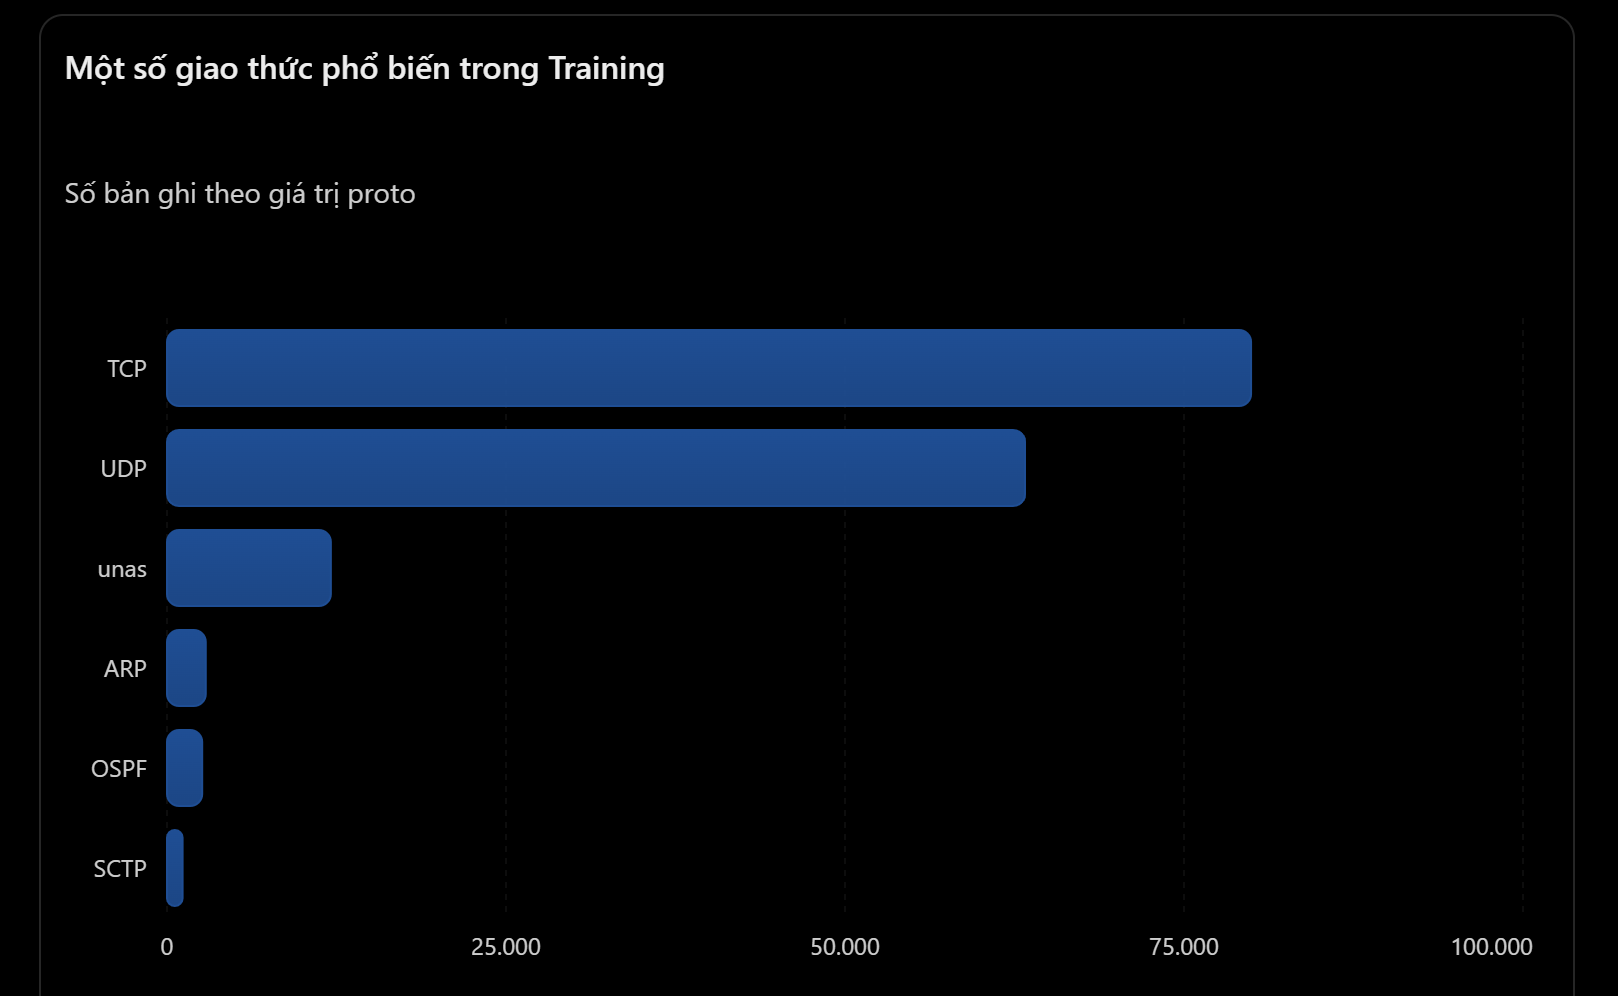
    - Trước mắt dùng TCP/UDP làm phạm vi nghiên cứu ứng viên cho mô hình flow-level đầu tiên, nhưng chưa loại 18,3% dữ liệu còn lại. Ta phải đo xem những loại tấn công nào sẽ bị ảnh hưởng trước khi quyết định.
- Vấn đề B — Duration bằng 0:
    - Điều này xác nhận hai cách tính đều cho 0 đối với sự kiện ICMP mẫu đang xét.
    - Nhưng chưa chứng minh Suricata không có độ chính xác thời gian.
    - Có thể flow đó thực sự rất ngắn, hoặc timestamp ghi trong mẫu không đủ để phân biệt hai thời điểm. Chúng ta cần khảo sát nhiều sự kiện, đặc biệt là flow TCP/UDP, trước khi quyết định dùng age hay hiệu end - start.

Ta đã xác nhận một mẫu sự kiện flow thực tế có thể cung cấp thống kê packet, byte, thời gian và giao thức. Tuy nhiên, chưa thể khẳng định các thống kê này tương đương hoàn toàn với UNSW-NB15.

Đối với mục tiêu đồ án:
- ML: cần bộ flow features có định nghĩa nhất quán giữa training và inference.
- DL: cần thêm timestamp và thông tin liên kết các flow thành chuỗi hành vi.
- Rule Generator: cần bằng chứng quan sát được, không thể chỉ dựa vào điểm bất thường của mô hình.
Khi xác minh xong các feature, chúng ta mới thực hiện Feature Selection, Correlation Analysis và Preprocessing. Những phép tính như StandardScaler sẽ chỉ được fit trên tập Training, sau đó dùng lại đúng tham số khi inference.

In [231]:
tcp_udp_mask = train_df["proto"].isin(["tcp", "udp"])

print("TCP/UDP:", tcp_udp_mask.sum())
print("Other:", (~tcp_udp_mask).sum())

print("\nPhân phối nhóm tấn công:")
display(
    pd.crosstab(
        train_df["attack_cat"],
        tcp_udp_mask,
        rownames=["Attack category"],
        colnames=["TCP/UDP"]
    )
)

TCP/UDP: 143229
Other: 32112

Phân phối nhóm tấn công:


TCP/UDP,False,True
Attack category,,
Analysis,1436,564
Backdoor,1446,300
DoS,9625,2639
Exploits,13080,20313
Fuzzers,1478,16706
Generic,285,39715
Normal,2957,53043
Reconnaissance,1805,8686
Shellcode,0,1133


- Giả sử một nhóm tấn công có 90% bản ghi thuộc TCP/UDP, nhưng nhóm khác chỉ có 20%. Khi đó, lọc TCP/UDP có thể làm một số nhóm tấn công gần như biến mất.

- Đối với đề tài phát hiện tấn công mới, chúng ta không được lựa chọn dữ liệu chỉ vì cách đó giúp việc huấn luyện dễ hơn. Phải biết phạm vi phát hiện thực sự sẽ bị giới hạn đến đâu.

In [232]:
print("Start:", flow.get("start"))
print("End:", flow.get("end"))
print("Age:", flow.get("age"))

print("Protocol:", event.get("proto"))
print("Flow state:", flow.get("state"))
print("Flow reason:", flow.get("reason"))

Start: 2026-10-25T10:35:59.946901+0000
End: 2026-10-25T10:35:59.946901+0000
Age: 0
Protocol: IPv6-ICMP
Flow state: new
Flow reason: timeout


- Vì chúng cung cấp ngữ cảnh về trạng thái và lý do Suricata ghi nhận kết thúc flow.
- Chúng ta cần hiểu sự kiện mình đang đọc trước khi diễn giải duration bằng 0.
- Nhưng một mẫu ICMP vẫn chưa đủ để xác nhận cách tính thời lượng của toàn bộ lưu lượng TCP/UDP.

### Phân tích kết quả trên:
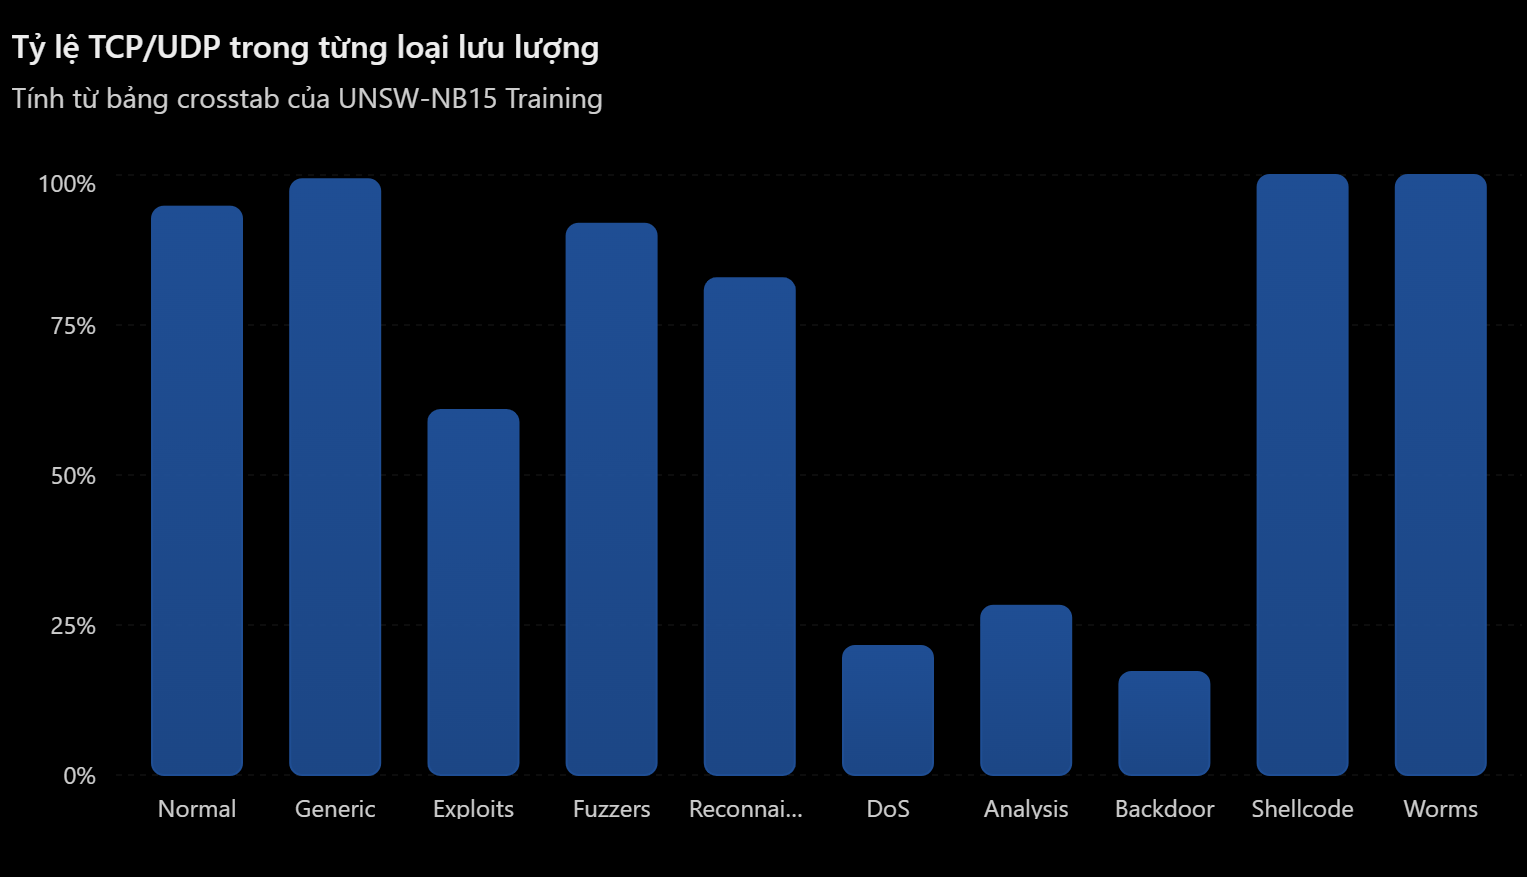

- Reconnaissance: 8.686/10.491 bản ghi thuộc TCP/UDP, khoảng 82,8%. Đây là tỷ lệ khá cao, phù hợp để bắt đầu xây dựng thí nghiệm cho kịch bản thăm dò mạng.
- DoS: Chỉ 2.639/12.264 bản ghi thuộc TCP/UDP, khoảng 21,5%. Nếu lọc TCP/UDP, chúng ta sẽ loại phần lớn bản ghi DoS hiện có.
- Normal: 53.043/56.000 bản ghi thuộc TCP/UDP, khoảng 94,7%. Đây là nguồn ứng viên để xây dựng mô hình Isolation Forest học hành vi bình thường trong phạm vi TCP/UDP.
- Kết luận: Nếu chỉ huấn luyện với TCP/UDP, ta phải công bố rằng mô hình này chỉ nghiên cứu lưu lượng trong phạm vi TCP/UDP. Không được dùng kết quả đó để tuyên bố phát hiện toàn bộ các loại DoS hay các giao thức khác.

#### Quyết định kỹ thuật:
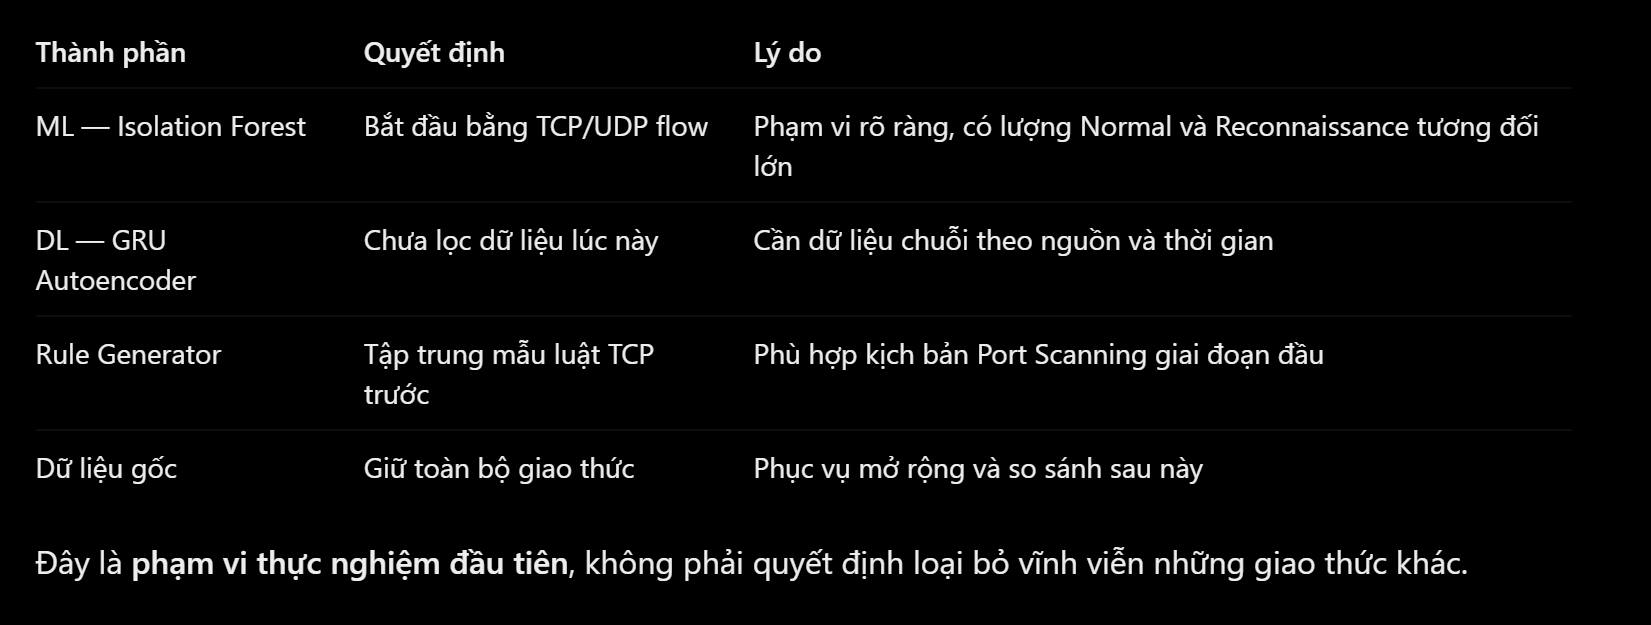

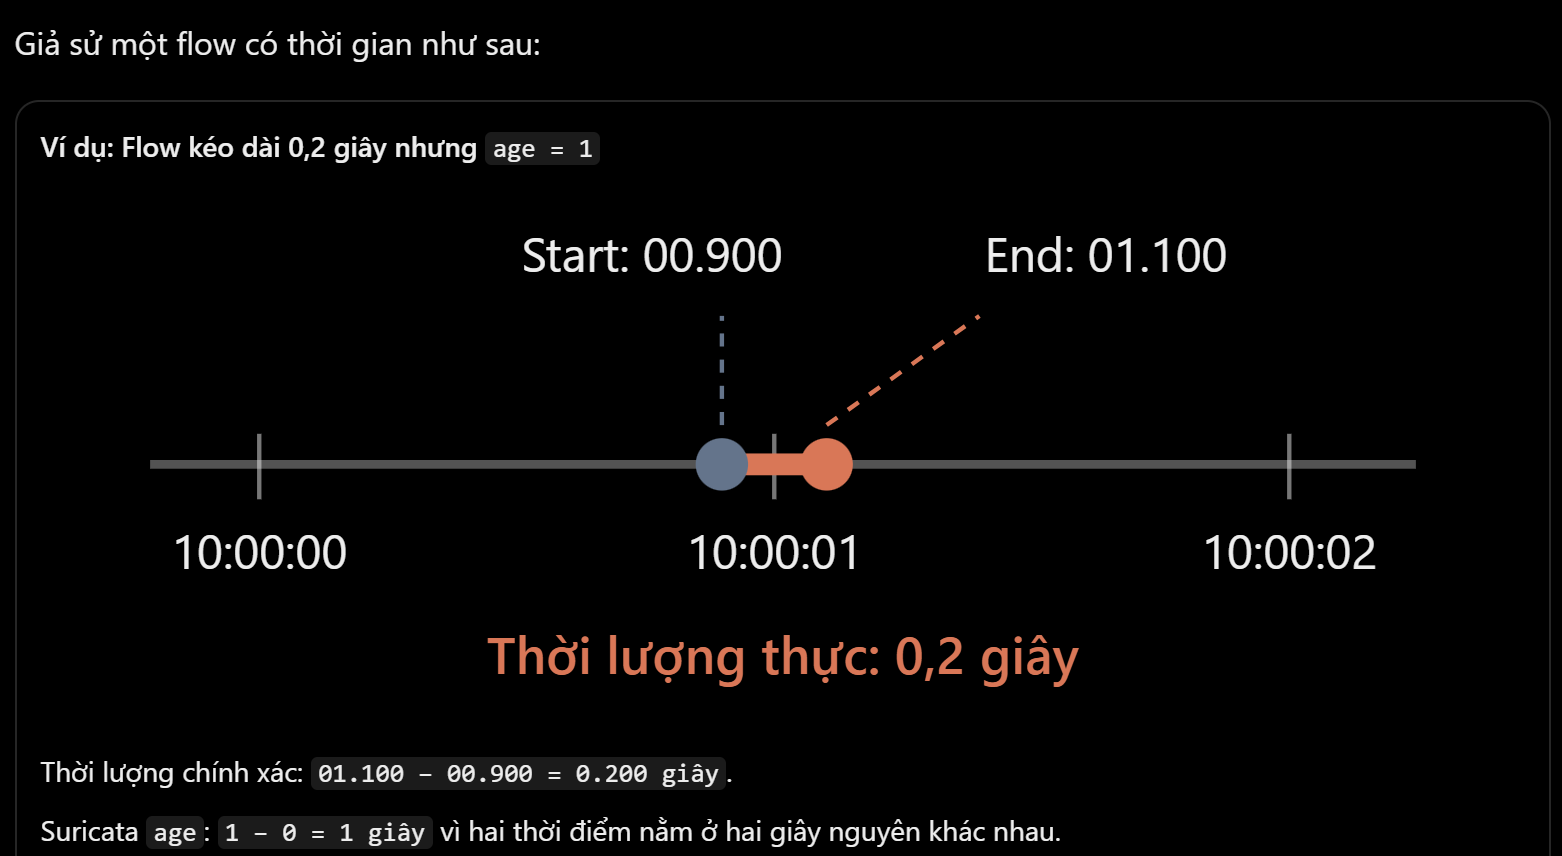

In [233]:
import sys

src_path = str(root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from netids.adapters.suricata import extract_duration, extract_flow_counters, derive_flow_totals, derive_flow_rates

In [234]:
test_event = {
    "flow": {
        "start": "2026-10-25T10:35:24.229017+0000",
        "end": "2026-10-25T10:35:24.278452+0000"
    }
}

result = extract_duration(test_event)

print("Duration:", result)

assert abs(result - 0.049435) < 1e-9

Duration: 0.049435


In [235]:
zero_event = {
    "flow": {
        "start": "2026-10-25T10:00:00+00:00",
        "end": "2026-10-25T10:00:00+00:00"
    }
}

assert extract_duration(zero_event) == 0.0

print("Zero duration: PASS")

Zero duration: PASS


In [236]:
invalid_event = {
    "flow": {
        "start": "2026-10-25T10:00:10+00:00",
        "end": "2026-10-25T10:00:05+00:00"
    }
}

try:
    extract_duration(invalid_event)
except ValueError:
    print("Invalid duration: PASS")
else:
    raise AssertionError("Expected ValueError")

Invalid duration: PASS


In [237]:
test_flow_event = {
    "flow": {
        "pkts_toserver": 6,
        "pkts_toclient": 4,
        "bytes_toserver": 258,
        "bytes_toclient": 172,
    }
}

counters = extract_flow_counters(test_flow_event)

display(counters)

{'pkts_toserver': 6,
 'pkts_toclient': 4,
 'bytes_toserver': 258,
 'bytes_toclient': 172}

In [238]:
invalid_flow_event = {
    "flow": {
        **test_flow_event["flow"],
        "pkts_toserver": -1,
    }
}

try:
    extract_flow_counters(invalid_flow_event)
except ValueError:
    print("Negative counter: PASS")
else:
    raise AssertionError("Expected ValueError")

Negative counter: PASS


### Feature Engineering: Tổng số packet và byte
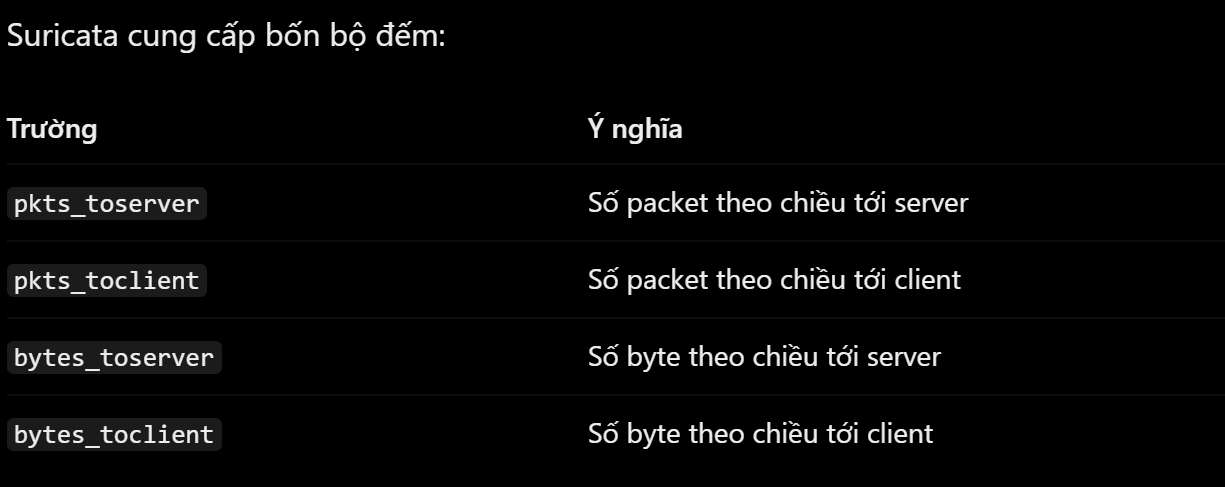

In [239]:
counters = extract_flow_counters(test_flow_event)

totals = derive_flow_totals(counters)

display(totals)

{'total_packets': 10, 'total_bytes': 430}

In [240]:
assert totals["total_packets"] == 10
assert totals["total_bytes"] == 430

print("Flow totals: PASS")

Flow totals: PASS


In [241]:
original = counters.copy()

derive_flow_totals(counters)

assert counters == original

print("Input unchanged: PASS")

Input unchanged: PASS


# Phân tích dữ liệu từ kết quả ở trên:

## 1. Mục tiêu

Xây dựng các hàm Python để trích xuất, kiểm tra và tính toán các đặc trưng lưu lượng mạng từ sự kiện `flow` trong Suricata EVE JSON.

Các đặc trưng này sẽ được sử dụng để xây dựng Feature Schema thống nhất phục vụ mô hình Machine Learning.

Ở giai đoạn này, chúng ta chưa huấn luyện mô hình và chưa thực hiện StandardScaler hoặc Feature Selection.

## 2. Định hướng xử lý dữ liệu

Hệ thống sử dụng hai nguồn dữ liệu chính:

- **Training:** Các bộ dữ liệu nghiên cứu, trước mắt là UNSW-NB15.
- **Inference:** Dữ liệu thực tế được Suricata ghi nhận qua EVE JSON.

Mỗi nguồn dữ liệu cần một bộ chuyển đổi riêng (Adapter) để đưa về cùng một Feature Schema.

Không đổi tên các field của Suricata thành field UNSW-NB15 nếu chưa xác minh được chúng tương đương về ngữ nghĩa, đơn vị và cách thống kê.

Mục tiêu cuối cùng là bảo đảm dữ liệu dùng để huấn luyện và dữ liệu đưa vào mô hình khi triển khai có cách biểu diễn nhất quán.

## 3. Phase 04.2.6 — Duration Extraction

### Vấn đề

Suricata cung cấp:

- `flow.start`: Thời điểm bắt đầu flow.
- `flow.end`: Thời điểm kết thúc quan sát flow.
- `flow.age`: Tuổi flow được biểu diễn bằng số giây nguyên.

Khi phân tích dữ liệu thực tế, chúng ta ghi nhận:

| Thời lượng từ timestamp | `flow.age` |
|---|---|
| 0.049435 giây | 0 |
| 20.764662 giây | 21 |
| 7.106195 giây | 8 |
| 71.819053 giây | 72 |
| 49.279170 giây | 50 |

Kết quả cho thấy `flow.age` không giữ được phần thời gian dưới một giây.

### Giải pháp

Xây dựng hàm `extract_duration(event)` để tính:

`duration_seconds = flow.end - flow.start`

Hàm sử dụng `datetime.fromisoformat()` để chuyển đổi timestamp và `total_seconds()` để lấy thời lượng dạng số thực.

### Kiểm tra dữ liệu

Hàm phải:

- Đọc được `flow.start` và `flow.end`.
- Yêu cầu timestamp có thông tin múi giờ.
- Chấp nhận duration bằng 0.
- Từ chối duration âm.
- Không tự ý thay dữ liệu lỗi bằng 0.

### Kết quả kiểm thử đã thực hiện

- Duration hợp lệ: `0.049435`.
- Duration bằng 0: PASS.
- Duration âm: PASS.

**Kết luận:** Hoàn thành hàm trích xuất thời lượng cơ bản. Cần bổ sung kiểm thử timestamp thiếu, sai định dạng và nhiều sự kiện thực tế trước khi dùng trong hệ thống vận hành.

## 4. Phase 04.2.7 — Flow Counter Extraction

### Vấn đề

Suricata có bốn bộ đếm lưu lượng theo hai chiều:

| Field | Ý nghĩa |
|---|---|
| `pkts_toserver` | Số packet theo chiều tới server |
| `pkts_toclient` | Số packet theo chiều tới client |
| `bytes_toserver` | Số byte theo chiều tới server |
| `bytes_toclient` | Số byte theo chiều tới client |

Các giá trị này cần được trích xuất và kiểm tra trước khi đưa vào pipeline xử lý dữ liệu.

### Giải pháp

Xây dựng hàm `extract_flow_counters(event)`.

Hàm thực hiện:

- Truy xuất đúng bốn field cần thiết.
- Kiểm tra giá trị có kiểu số nguyên.
- Không chấp nhận Boolean thay cho số nguyên.
- Từ chối giá trị âm.
- Không tự động thay field bị thiếu bằng 0.

### Kết quả kiểm thử đã thực hiện

Đầu vào hợp lệ:

```python
{
    "pkts_toserver": 6,
    "pkts_toclient": 4,
    "bytes_toserver": 258,
    "bytes_toclient": 172
}
```

Hàm trả về đúng bốn giá trị.

Kiểm thử packet âm cho kết quả PASS.

**Kết luận:** Hàm trích xuất và kiểm tra bốn bộ đếm đã vượt qua các trường hợp cơ bản được kiểm thử. Chưa xác minh hoàn toàn sự tương đương giữa các bộ đếm này và `spkts`, `dpkts`, `sbytes`, `dbytes` trong UNSW-NB15.

## 5. Phase 04.2.8 — Derived Flow Features

### Vấn đề

Ngoài số packet và byte theo từng chiều, chúng ta muốn có những feature thể hiện tổng quy mô trao đổi dữ liệu của một flow.

### Giải pháp đề xuất

Xây dựng hàm `derive_flow_totals(counters)`.

Hai feature dẫn xuất:

`total_packets = pkts_toserver + pkts_toclient`

`total_bytes = bytes_toserver + bytes_toclient`

Ví dụ:

- `total_packets = 6 + 4 = 10`
- `total_bytes = 258 + 172 = 430`

### Lý do tách thành hàm riêng

`extract_flow_counters()` chịu trách nhiệm đọc và kiểm tra dữ liệu gốc.

`derive_flow_totals()` chịu trách nhiệm tính toán các đặc trưng dẫn xuất.

Việc phân tách giúp code dễ kiểm thử, dễ bảo trì và hạn chế việc một hàm đảm nhiệm quá nhiều nhiệm vụ.

### Trạng thái

Đã thiết kế hàm và bài kiểm thử.

**Chưa có kết quả thực thi do người phát triển xác nhận** đối với hai kiểm thử:

- `Flow totals: PASS`
- `Input unchanged: PASS`

Do đó chưa đánh dấu Phase 04.2.8 là hoàn thành.

## 6. Tại sao chưa chuẩn hóa bằng StandardScaler?

Các bước hiện tại thuộc **Feature Extraction** và **Feature Engineering**, không phải chuẩn hóa thang đo thống kê.

Cần phân biệt:

- **Feature Extraction:** Lấy thông tin từ Suricata.
- **Feature Engineering:** Tính thêm các đặc trưng từ dữ liệu đã lấy.
- **Feature Mapping:** Xác minh các đặc trưng giữa những nguồn dữ liệu.
- **Feature Selection:** Chọn những đặc trưng phù hợp với bài toán.
- **Feature Scaling:** Biến đổi thang đo của feature khi phương pháp học máy cần.

Các tham số tiền xử lý có học từ dữ liệu phải được xác định trên Training và tái sử dụng khi inference.

## 7. Ý nghĩa đối với đề tài

Các hàm đang xây dựng là phần nền tảng giúp mô hình học máy có thể tiếp nhận dữ liệu Suricata thực tế, thay vì chỉ thực hiện thí nghiệm offline trên CSV.

Tuy nhiên, việc xây dựng Feature Extractor chưa chứng minh mô hình có khả năng phát hiện tấn công mới.

Đề tài còn phải:

- Xác minh tính tương thích của các feature giữa tập huấn luyện và Suricata.
- Xây dựng dữ liệu theo chuỗi thời gian cho nhánh Deep Learning.
- Huấn luyện và đánh giá mô hình trên các tập dữ liệu phù hợp.
- Tạo luật Suricata ứng viên từ bằng chứng phát hiện.
- Kiểm tra cú pháp và hiệu quả luật trước khi triển khai.

## 8. Những việc cần làm tiếp theo

1. Kiểm thử hàm `derive_flow_totals()`.
2. Hoàn thiện và kiểm thử các hàm trích xuất.
3. Xác minh Feature Mapping giữa Suricata và UNSW-NB15.
4. Xem xét các feature tốc độ và cách xử lý duration bằng 0.
5. Xây dựng Feature Schema phiên bản đầu tiên.
6. Thực hiện Correlation Analysis, Feature Selection và Preprocessing trước khi huấn luyện.

## 9. Ghi nhớ

**Dữ liệu nguồn → Adapter → Feature Schema thống nhất → Preprocessing → Machine Learning.**

Không được nhầm Feature Engineering với StandardScaler.

Không được coi hai feature tương đương chỉ vì có tên hoặc giá trị gần giống nhau.

Không được đánh dấu một bước là hoàn thành nếu chưa chạy và xác nhận kết quả kiểm thử.

### Flow Rate Engineering: Kỹ thuật lưu lượng

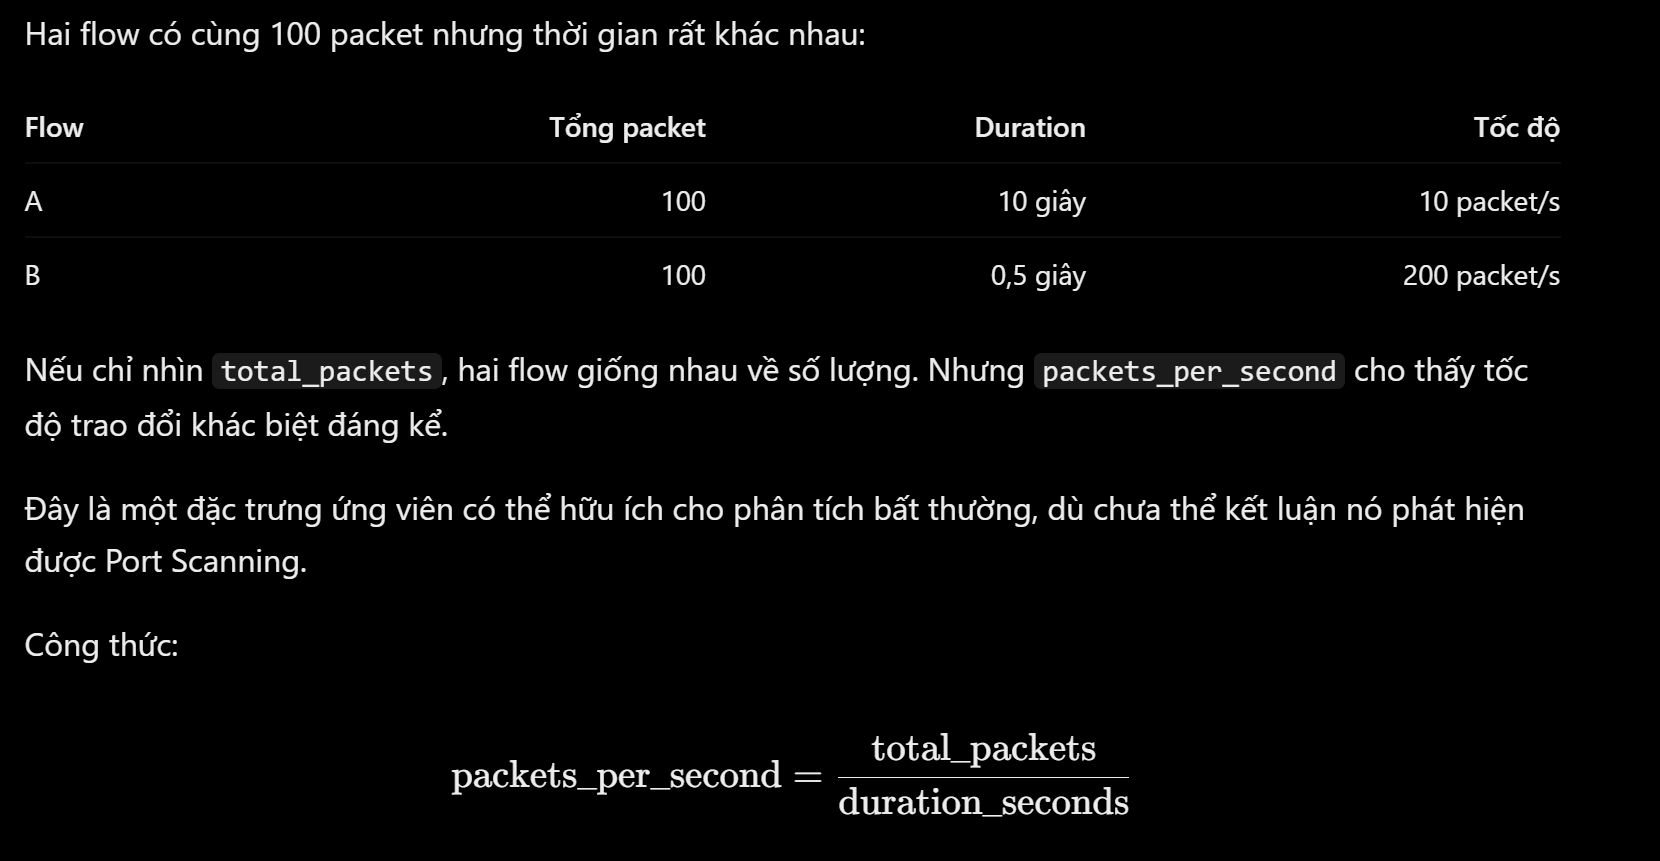

In [242]:
examples = [
    (100, 10.0),
    (100, 0.5),
    (100, 0.0),
    (100, 0.000001),
]

for packets, duration in examples:
    rate = packets / duration if duration > 0 else None

    print(
        f"packets={packets}, "
        f"duration={duration}, "
        f"rate={rate}"
    )

packets=100, duration=10.0, rate=10.0
packets=100, duration=0.5, rate=200.0
packets=100, duration=0.0, rate=None
packets=100, duration=1e-06, rate=100000000.0


Có hai điều cần phân biệt:

Trường hợp duration = 0: Không thể thực hiện phép chia. Chúng ta dùng None để biểu diễn tốc độ chưa xác định, không phải 0 packet/giây.

Trường hợp duration rất nhỏ: Phép tính vẫn đúng về mặt toán học, nhưng kết quả có thể rất lớn và không phản ánh tốc độ truyền ổn định trong toàn bộ kết nối.

Ví dụ, nếu một flow chỉ có vài packet trong khoảng microsecond thì tốc độ trung bình tính bằng phép chia có thể tăng đột biến. Điều này không tự động chứng minh có tấn công.

Đặc biệt với đề tài Port Scanning, chúng ta cần phân biệt:
- packets_per_second của một flow: số packet của flow chia cho thời lượng flow.
- connections_per_minute của một IP nguồn: số kết nối được quan sát trong một phút.
Hai chỉ số này khác nhau. Chỉ số thứ hai có thể phản ánh hành vi quét cổng rõ hơn, nhưng cần tổng hợp nhiều flow theo thời gian.

Tạm thời giữ None cho kết quả duration = 0

In [243]:
totals = {
    "total_packets": 100,
    "total_bytes": 1000,
}

rates = derive_flow_rates(totals, 0.5)

print(rates)

assert rates["packets_per_second"] == 200
assert rates["bytes_per_second"] == 2000

print("Normal flow rate: PASS")

{'packets_per_second': 200.0, 'bytes_per_second': 2000.0}
Normal flow rate: PASS


In [244]:
zero_rates = derive_flow_rates(totals, 0.0)

assert zero_rates["packets_per_second"] is None
assert zero_rates["bytes_per_second"] is None

print("Zero duration: PASS")

Zero duration: PASS


In [245]:
try:
    derive_flow_rates(totals, -1.0)
except ValueError:
    print("Negative duration: PASS")
else:
    raise AssertionError("Expected ValueError")

Negative duration: PASS


In [246]:
from netids.adapters.suricata import extract_flow_features

features = extract_flow_features(event)

display(features)

{'duration_seconds': 0.0,
 'pkts_toserver': 1,
 'pkts_toclient': 0,
 'bytes_toserver': 86,
 'bytes_toclient': 0,
 'total_packets': 1,
 'total_bytes': 86,
 'packets_per_second': None,
 'bytes_per_second': None}

In [247]:
assert features["duration_seconds"] == 0.0
assert features["total_packets"] == 1
assert features["total_bytes"] == 86
assert features["packets_per_second"] is None

print("Integrated Feature Extractor: PASS")

Integrated Feature Extractor: PASS


In [248]:
import pandas as pd

mapping = pd.DataFrame([
    ("dur", "duration_seconds", "Need verification"),
    ("spkts", "pkts_toserver", "Need verification"),
    ("dpkts", "pkts_toclient", "Need verification"),
    ("sbytes", "bytes_toserver", "Need verification"),
    ("dbytes", "bytes_toclient", "Need verification"),
    ("proto", "protocol", "Need normalization"),
], columns=[
    "unsw_feature",
    "canonical_feature",
    "status"
])

display(mapping)

,unsw_feature,canonical_feature,status
0,dur,duration_seconds,Need verification
1,spkts,pkts_toserver,Need verification
2,dpkts,pkts_toclient,Need verification
3,sbytes,bytes_toserver,Need verification
4,dbytes,bytes_toclient,Need verification
5,proto,protocol,Need normalization


## Mapping ứng viên:
- unsw_feature: tên cột trong UNSW-NB15.
- canonical_feature: tên đặc trưng mà hệ thống dự định sử udngj thống nhất.
- status: tifmh trạng xác minh tính tương đồng.

#### Lưu ý: Làm trước StandardScaler: Vì trước khi chuẩn hóa giá tị số, ta cần phải biết giá trị đó thực sự đo cùng 1 đại lượng hay không?
----

In [249]:
print(
    "Các feature UNSW tồn tại:",
    mapping["unsw_feature"].isin(train_df.columns).all()
)

display(
    train_df[mapping["unsw_feature"].tolist()].head()
)

Các feature UNSW tồn tại: True


,dur,spkts,dpkts,sbytes,dbytes,proto
0,0.121478,6,4,258,172,tcp
1,0.649902,14,38,734,42014,tcp
2,1.623129,8,16,364,13186,tcp
3,1.681642,12,12,628,770,tcp
4,0.449454,10,6,534,268,tcp


In [250]:
cic_path = (
    root / "data" / "raw" / "cic-ids2017"
    / "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

cic_sample = pd.read_csv(cic_path, nrows=5)

print("Tổng số cột CIC:", len(cic_sample.columns))

keywords = [
    "duration", "packet", "byte",
    "pkt", "flow", "protocol"
]

# Một số tên cột trong CIC-IDS2017 có khoảng trắng đầu hoặc cuối.
    # Ví dụ, " Flow Duration" và "Flow Duration" trông gần giống nhau nhưng Python coi là hai tên khác nhau.
for column in cic_sample.columns:
    name = column.strip()

    if any(word in name.lower() for word in keywords):
        print(repr(name))

Tổng số cột CIC: 79
'Flow Duration'
'Total Fwd Packets'
'Total Backward Packets'
'Total Length of Fwd Packets'
'Total Length of Bwd Packets'
'Fwd Packet Length Max'
'Fwd Packet Length Min'
'Fwd Packet Length Mean'
'Fwd Packet Length Std'
'Bwd Packet Length Max'
'Bwd Packet Length Min'
'Bwd Packet Length Mean'
'Bwd Packet Length Std'
'Flow Bytes/s'
'Flow Packets/s'
'Flow IAT Mean'
'Flow IAT Std'
'Flow IAT Max'
'Flow IAT Min'
'Fwd Packets/s'
'Bwd Packets/s'
'Min Packet Length'
'Max Packet Length'
'Packet Length Mean'
'Packet Length Std'
'Packet Length Variance'
'Average Packet Size'
'Fwd Avg Bytes/Bulk'
'Fwd Avg Packets/Bulk'
'Bwd Avg Bytes/Bulk'
'Bwd Avg Packets/Bulk'
'Subflow Fwd Packets'
'Subflow Fwd Bytes'
'Subflow Bwd Packets'
'Subflow Bwd Bytes'
'Init_Win_bytes_forward'
'Init_Win_bytes_backward'
'act_data_pkt_fwd'


#### Có ba điểm cần đặc biệt chú ý:
- Thời lượng: CIC-IDS2017 thường biểu diễn Flow Duration bằng microsecond, trong khi schema dự kiến sử dụng giây. Cần xác minh và chuyển đổi đơn vị.
- Chiều dữ liệu: Fwd/Bwd không mặc nhiên tương đương toserver/toclient. Phải kiểm tra hướng khởi tạo flow và cách xác định client/server.
- Số byte: Total Length of Fwd Packets không mặc nhiên tương đương bytes_toserver. Nếu một nguồn tính payload bytes còn nguồn kia tính toàn bộ packet bytes, chúng ta không thể chỉ đổi tên cột.

##### Kết luận: Điều này cũng có nghĩa: chúng ta chưa nên gộp CIC-IDS2017 vào UNSW-NB15 để huấn luyện.

### Sau khi khảo sát các dataset, mappping sẽ có dạng:
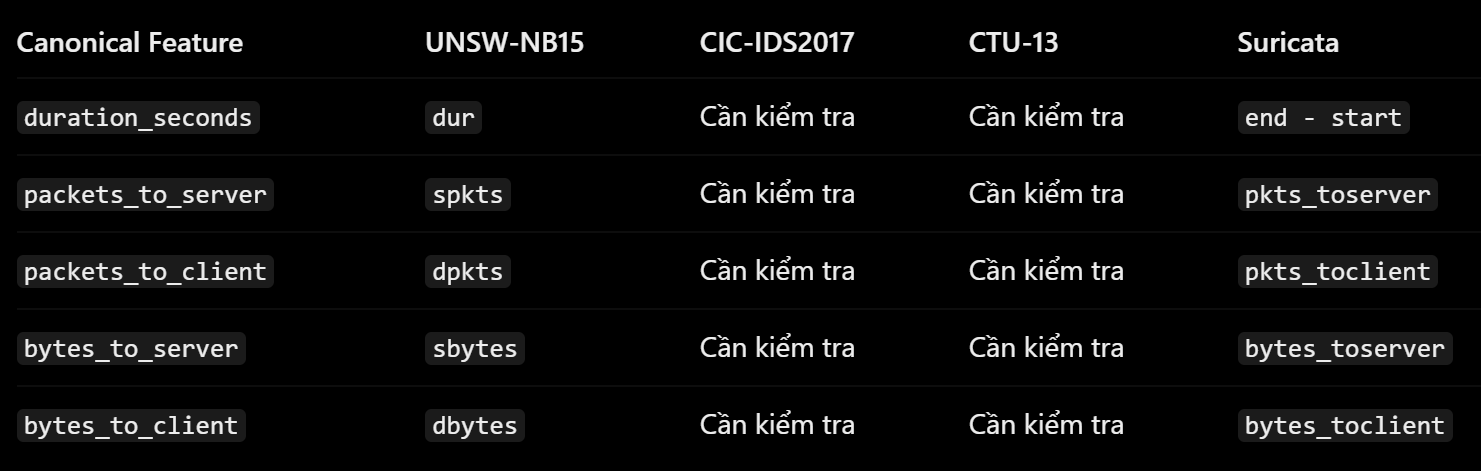

- Bảng này hiện chỉ thể hiện các nguồn và trường ứng viên. Chúng ta sẽ chốt tên schema cùng trạng thái Verified, Derived, Unsupported sau khi đối chiếu định nghĩa.

- Quan trọng hơn, không nhất thiết mọi dataset đều phải đi vào cùng một mô hình huấn luyện. Nếu có sự khác biệt không thể khắc phục, chúng ta sẽ dùng các bộ dữ liệu đó để đánh giá độc lập hoặc cho những nhiệm vụ khác nhau.

In [251]:
selected_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
]

raw_columns = [
    next(c for c in cic_sample.columns if c.strip() == name)
    for name in selected_features
]

display(cic_sample[raw_columns])

print("\nData types:")
print(cic_sample[raw_columns].dtypes)

,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s
0,3,2,0,12,0,4.000000e+06,666666.66670
1,109,1,1,6,6,1.100917e+05,18348.62385
2,52,1,1,6,6,2.307692e+05,38461.53846
3,34,1,1,6,6,3.529412e+05,58823.52941
4,3,2,0,12,0,4.000000e+06,666666.66670



Data types:
 Flow Duration                    int64
 Total Fwd Packets                int64
 Total Backward Packets           int64
Total Length of Fwd Packets       int64
 Total Length of Bwd Packets      int64
Flow Bytes/s                    float64
 Flow Packets/s                 float64
dtype: object


In [252]:
import csv
from collections import Counter

with open(cic_path, encoding="utf-8-sig", newline="") as f:
    header = next(csv.reader(f))

normalized_header = [name.strip() for name in header]

duplicates = {
    name: count
    for name, count in Counter(normalized_header).items()
    if count > 1
}

print("Raw columns:", len(header))
print("Duplicate column names:", duplicates)

Raw columns: 79
Duplicate column names: {'Fwd Header Length': 2}


In [253]:
ctu_path = (
    root / "data" / "raw" / "ctu-13"
    / "capture20110815-2.binetflow"
)

ctu_sample = pd.read_csv(ctu_path, nrows=5)

print("Số cột:", len(ctu_sample.columns))
print("\nDanh sách cột:")
print(ctu_sample.columns.tolist())

print("\n5 dòng đầu:")
display(ctu_sample.head())

print("\nKiểu dữ liệu:")
print(ctu_sample.dtypes)

Số cột: 15

Danh sách cột:
['StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir', 'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes', 'Label']

5 dòng đầu:


,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label
0,2011/08/15 16:43:20.931208,1783.916870,tcp,147.32.84.59,64131,<?>,164.8.32.159,54992,PA_PA,0,0,293,32160,20485,flow=Background-Established-cmpgw-CVUT
1,2011/08/15 16:43:20.933428,0.444453,tcp,147.32.87.252,49218,<?>,147.32.80.13,3128,FPA_FPA,0,0,879,747909,19566,flow=To-Background-CVUT-Proxy
2,2011/08/15 16:43:20.933441,1804.837158,tcp,41.143.58.184,1328,<?>,147.32.86.179,58675,PA_PA,0,0,9547,942226,580940,flow=Background
3,2011/08/15 16:43:20.933541,0.187604,tcp,147.32.86.155,51273,<?>,204.154.94.81,80,FA_FA,0,0,3,198,132,flow=Background
4,2011/08/15 16:43:20.933942,1804.610718,tcp,147.32.86.179,58675,<?>,151.42.234.124,50001,PA_PA,0,0,29890,3689108,917036,flow=Background



Kiểu dữ liệu:
StartTime        str
Dur          float64
Proto            str
SrcAddr          str
Sport          int64
Dir              str
DstAddr          str
Dport          int64
State            str
sTos           int64
dTos           int64
TotPkts        int64
TotBytes       int64
SrcBytes       int64
Label            str
dtype: object


Tốt! Chúng ta đã khảo sát cấu trúc ban đầu của cả ba bộ dữ liệu: UNSW-NB15, CIC-IDS2017 và CTU-13.

Kết quả CTU-13 lần này đặc biệt quan trọng, vì nó có những thông tin mà UNSW-NB15 Training/Testing đang sử dụng không cung cấp đầy đủ: IP nguồn, IP đích, cổng và thời gian bắt đầu flow.

Điều này giúp chúng ta phân biệt rõ hơn dữ liệu nào có thể phục vụ ML theo từng flow và dữ liệu nào có thể phục vụ DL theo chuỗi hành vi.

# 1. Phân tích kết quả CTU-13

Bạn đã xác minh file `capture20110815-2.binetflow` có 15 cột.

| Field CTU-13         | Ý nghĩa                     | Khả năng sử dụng                                  |
| -------------------- | --------------------------- | ------------------------------------------------- |
| `StartTime`          | Thời gian bắt đầu flow      | Sắp xếp, tổng hợp theo thời gian                  |
| `Dur`                | Thời lượng flow, giây       | Feature `duration_seconds` ứng viên               |
| `Proto`              | Giao thức                   | Feature `protocol`                                |
| `SrcAddr`, `DstAddr` | IP nguồn, IP đích           | Nhóm hoạt động theo host                          |
| `Sport`, `Dport`     | Cổng nguồn, đích            | Phân tích hành vi kết nối                         |
| `Dir`                | Hướng giao tiếp được mã hóa | Cần diễn giải trước khi ánh xạ                    |
| `TotPkts`            | Tổng số packet              | `total_packets` ứng viên                          |
| `TotBytes`           | Tổng số byte                | `total_bytes` ứng viên                            |
| `SrcBytes`           | Byte gửi từ nguồn           | Feature theo chiều nguồn, cần đối chiếu           |
| `State`              | Trạng thái flow             | Feature bổ sung tiềm năng                         |
| `Label`              | Nhãn lưu lượng              | Đánh giá mô hình, không đưa trực tiếp vào đầu vào |

Các định nghĩa chính này phù hợp với tài liệu CTU-13 và mô tả định dạng Argus của Stratosphere Laboratory.&#x20;




## 2. Điểm quan trọng nhất: CTU-13 có thể phục vụ nghiên cứu DL theo chuỗi

Giả sử chúng ta muốn phát hiện một IP liên tục thử kết nối đến nhiều cổng.

Thay vì chỉ xem một flow, hệ thống có thể nghiên cứu một chuỗi:

Ví dụ minh họa: Các flow của cùng một IP nguồn

10:00:01 -> Cổng 21

10:00:02 -> Cổng 22

10:00:03 -> Cổng 23

Đây chỉ là ví dụ về chuỗi cần nghiên cứu, không phải bản ghi đã tìm thấy trong CTU-13.

Với các trường `SrcAddr`, `Dport`, `StartTime`, chúng ta có thể nghiên cứu những đặc trưng như số flow theo cửa sổ thời gian, số cổng đích khác nhau và tần suất kết nối.

Tuy nhiên, cần lưu ý hai giới hạn:

- CTU-13 chủ yếu phục vụ nghiên cứu botnet, không được mặc nhiên coi nhãn Botnet là nhãn Port Scanning.&#x20;

- Một số flow kéo dài hơn 1.800 giây trong mẫu của bạn. Vì vậy, cần phân biệt thời gian bắt đầu flow và thời điểm flow thực sự hoàn tất khi xây pipeline xử lý theo thời gian.

Điều này có nghĩa CTU-13 là nguồn dữ liệu ứng viên cho DL theo chuỗi, chưa phải dataset DL đã được chốt.

# 3. Bảng tổng hợp ba dataset và Suricata

Bây giờ chúng ta đã có bức tranh tổng quan:

| Đặc trưng         | UNSW-NB15                        | CIC-IDS2017                    | CTU-13                                                | Suricata        |
| ----------------- | -------------------------------- | ------------------------------ | ----------------------------------------------------- | --------------- |
| Duration          | `dur`                            | `Flow Duration`                | `Dur`                                                 | `end - start`   |
| Protocol          | `proto`                          | Chưa xác nhận từ file này      | `Proto`                                               | `proto`         |
| Tổng packet       | Tính từ `spkts + dpkts`          | Tính từ Fwd + Bwd              | `TotPkts`                                             | Tổng hai chiều  |
| Tổng byte         | Tính từ `sbytes + dbytes`        | Tính từ Fwd + Bwd              | `TotBytes`                                            | Tổng hai chiều  |
| Packet từng chiều | Có                               | Có                             | Không có trực tiếp trong 15 cột                       | Có              |
| Byte từng chiều   | Có                               | Có                             | Có `SrcBytes`; chiều còn lại cần xác minh phép suy ra | Có              |
| IP nguồn/đích     | Không có trong hai CSV đang dùng | Cần kiểm tra                   | Có                                                    | Có trên TCP mẫu |
| Thời điểm bắt đầu | Không có trong hai CSV đang dùng | Cần kiểm tra                   | Có                                                    | Có              |
| Cổng nguồn/đích   | Không có trong hai CSV đang dùng | Có thể có, cần kiểm tra header | Có                                                    | Có trên TCP mẫu |

Đây là bảng về mức độ sẵn có của dữ liệu, chưa phải xác nhận các đại lượng hoàn toàn tương đương.

Điểm đáng chú ý là chúng ta không nên ép mọi dataset có cùng toàn bộ feature. Hợp lý hơn là xây:

- Một Flow Feature Schema cho ML.
- Một Sequence Feature Schema cho DL, sử dụng dữ liệu có IP và timestamp.

# 4. Tiếp tục Phase 04.3.4 — Kiểm tra nhãn và tính nhất quán CTU-13

Trước khi quyết định sử dụng CTU-13, có hai vấn đề cần xác minh.

Thứ nhất: Nhãn `Background` có nghĩa là gì?

Trong CTU-13, `Background` không đồng nghĩa chắc chắn với `Normal`. Theo Stratosphere Laboratory, Background là lưu lượng còn lại mà họ không thể khẳng định hoàn toàn là bình thường hay độc hại.&#x20;



Vì vậy, ta không được tự động gộp `Background` vào `Normal` khi huấn luyện mô hình học hành vi bình thường.

Thứ hai: `SrcBytes` có hợp lệ để suy ra byte chiều còn lại không?

Về mặt số học, nếu `SrcBytes` là một phần của `TotBytes`, thì có thể tính:

\\[ \text{DstBytes}=\text{TotBytes}-\text{SrcBytes} \\]

Nhưng trước khi làm điều đó, cần xác minh dữ liệu không có giá trị bất thường và ngữ nghĩa hai bộ đếm nhất quán.

## 5. Tiến độ Phase 04

| Bước                                   | Trạng thái                               |
| -------------------------------------- | ---------------------------------------- |
| 04.1 — Data Quality Profiling          | Đã thực hiện các kiểm tra chính của UNSW |
| 04.2 — Suricata Feature Extractor      | Đã PASS phiên bản cơ bản                 |
| 04.3.1 — UNSW Schema Inventory         | Hoàn thành                               |
| 04.3.2 — CIC Schema Inventory          | Hoàn thành khảo sát ban đầu              |
| 04.3.3 — CTU Schema Inventory          | Hoàn thành khảo sát ban đầu              |
| 04.3.4 — CTU Label & Consistency       | Đang thực hiện                           |
| 04.3.5 — Chốt Schema chung             | Chưa                                     |
| 04.4 — Correlation & Feature Selection | Chưa                                     |
| 04.5 — Preprocessing                   | Chưa                                     |
| 04.6 — Kiểm thử pipeline               | Chưa                                     |

Chúng ta đã có đủ thông tin ban đầu để không cần tiếp tục khám phá thêm nhiều feature một cách thiếu định hướng. Việc tiếp theo nên tập trung vào kiểm chứng dữ liệu, xác định phần giao nhau có ý nghĩa giữa các nguồn và chốt schema cho từng nhánh.

Bạn chạy ô code ở mục 4 và gửi kết quả. Sau đó mình sẽ hướng dẫn kiểm tra toàn bộ CTU-13 theo chunk, rồi chúng ta bắt đầu chốt Canonical Feature Schema v1, một quyết định kỹ thuật quan trọng cần ghi rõ trong README Phase 04.

In [254]:
print("Nhãn trong mẫu:")
display(ctu_sample["Label"].value_counts())

print("\nGiá trị hướng giao tiếp:")
display(ctu_sample["Dir"].value_counts())

print("\nKiểm tra byte:")
print(
    "SrcBytes > TotBytes:",
    (ctu_sample["SrcBytes"] > ctu_sample["TotBytes"]).sum()
)

print(
    "SrcBytes âm:",
    (ctu_sample["SrcBytes"] < 0).sum()
)

Nhãn trong mẫu:


Label
flow=Background                           3
flow=Background-Established-cmpgw-CVUT    1
flow=To-Background-CVUT-Proxy             1
Name: count, dtype: int64


Giá trị hướng giao tiếp:


Dir
<?>    5
Name: count, dtype: int64


Kiểm tra byte:
SrcBytes > TotBytes: 0
SrcBytes âm: 0


### Bản nhóm nhãn trong CTU-13
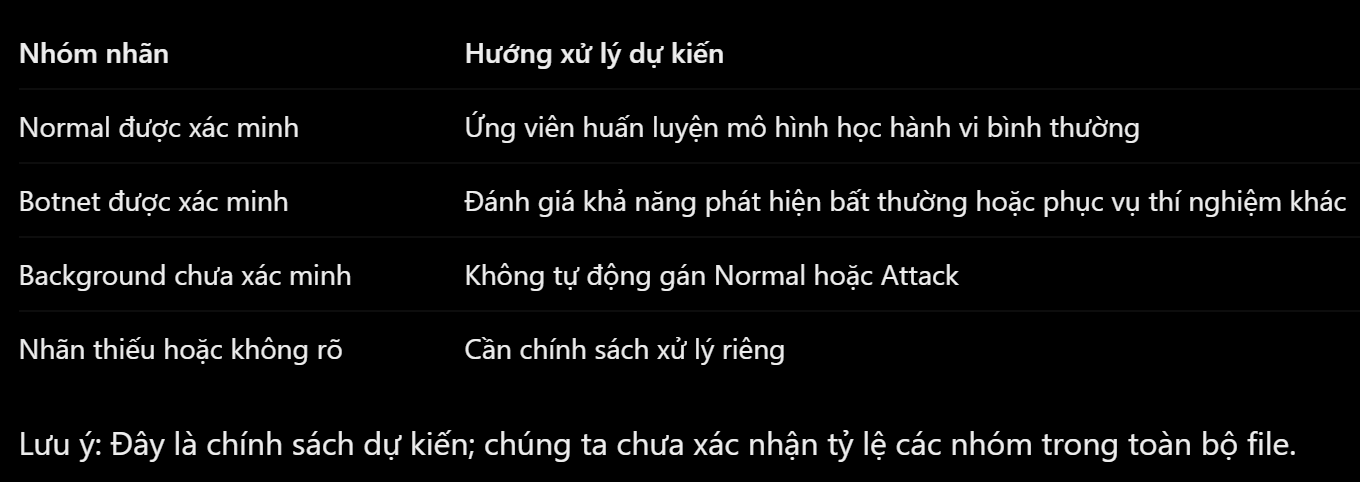

In [255]:
from collections import Counter

label_counts = Counter()
dir_counts = Counter()
total_rows = 0

for chunk in pd.read_csv(
    ctu_path,
    usecols=["Label", "Dir"],
    chunksize=50_000
):
    total_rows += len(chunk)

    labels = chunk["Label"].fillna("<MISSING>")
    directions = chunk["Dir"].fillna("<MISSING>").str.strip()

    label_counts.update(labels.value_counts().to_dict())
    dir_counts.update(directions.value_counts().to_dict())

print("Tổng số bản ghi:", total_rows)

print("\nTop 15 nhãn:")
for label, count in label_counts.most_common(15):
    print(count, "|", label)

print("\nPhân phối hướng giao tiếp:")
for direction, count in dir_counts.most_common():
    print(repr(direction), ":", count)

Tổng số bản ghi: 129832

Top 15 nhãn:
50817 | flow=To-Background-UDP-CVUT-DNS-Server
37203 | flow=Background-UDP-Established
15156 | flow=Background-TCP-Established
9331 | flow=Background-Established-cmpgw-CVUT
3426 | flow=Background
2893 | flow=Background-UDP-Attempt
1847 | flow=Background-TCP-Attempt
1810 | flow=From-Normal-V46-Stribrek
1722 | flow=From-Normal-V46-Grill
1340 | flow=To-Background-CVUT-Proxy
1107 | flow=From-Normal-V46-Jist
470 | flow=Background-Attempt-cmpgw-CVUT
422 | flow=From-Botnet-V46-TCP-Attempt
317 | flow=Background-UDP-NTP-Established-1
254 | flow=To-Background-CVUT-WebServer

Phân phối hướng giao tiếp:
'<->' : 92606
'->' : 34748
'<?>' : 1512
'<-' : 570
'?>' : 325
'who' : 71


### Phân tích kết quả CTU-13
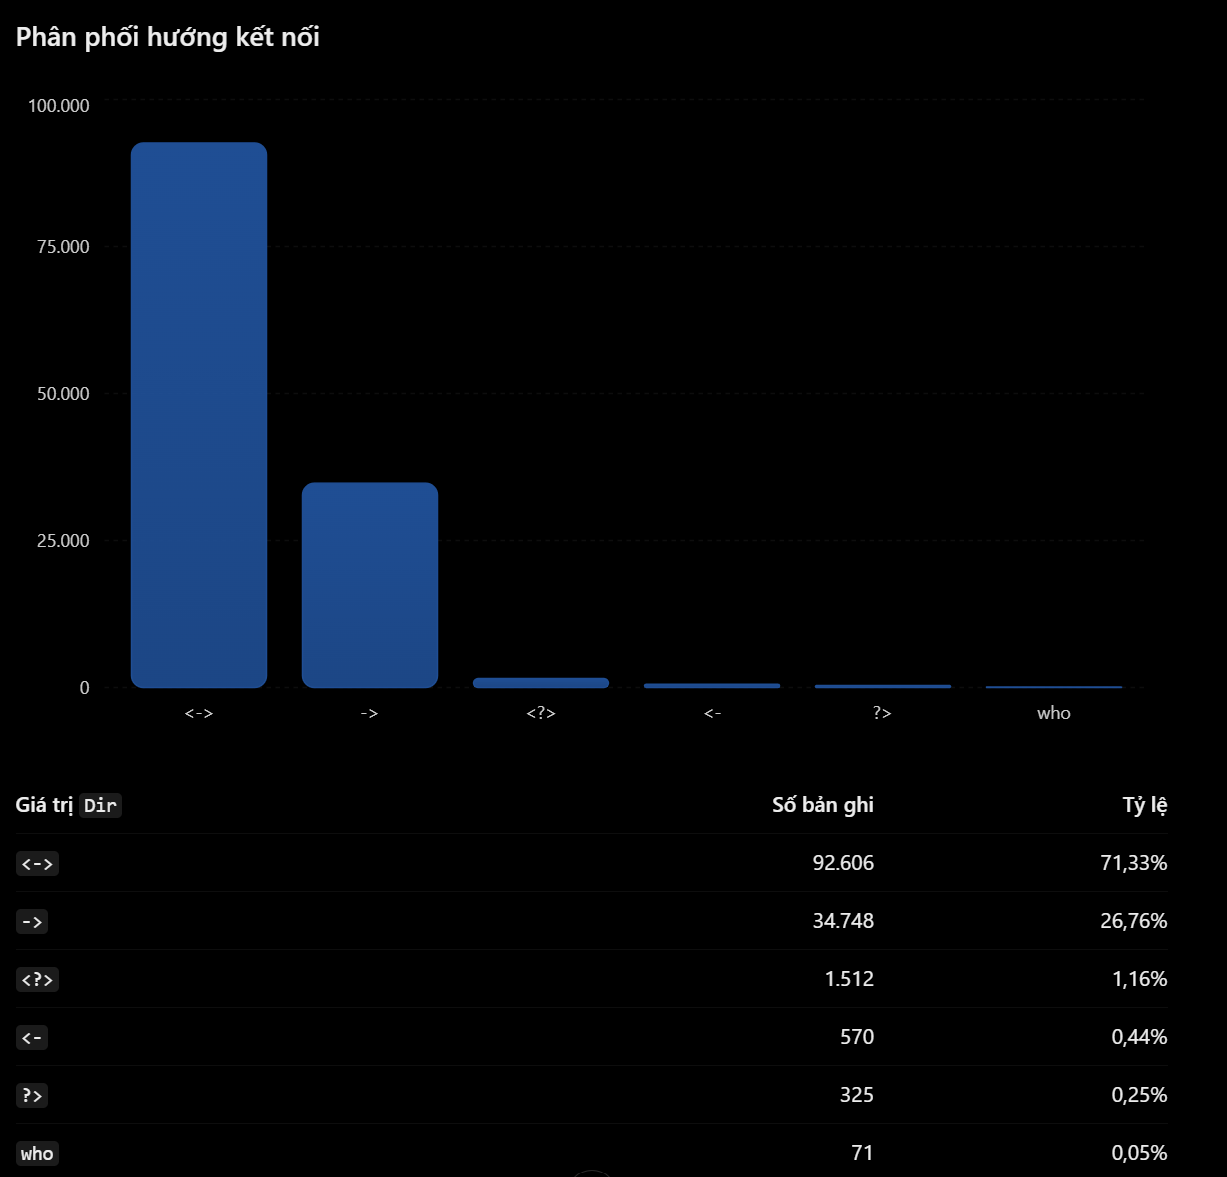

Chúng ta tạm thời phân định vai trò các nguồn dữ liệu:

| Nguồn | Vai trò nghiên cứu dự kiến |
| :--- | :--- |
| **UNSW-NB15** | ML phát hiện bất thường theo từng flow |
| **CIC-IDS2017** | Kiểm tra feature mapping và nghiên cứu tấn công DDoS/PortScan |
| **CTU-13** | Nghiên cứu chuỗi hành vi theo thời gian, phục vụ nhánh DL |
| **Suricata EVE JSON** | Dữ liệu thực tế để kiểm thử trích xuất feature và triển khai |

*Lưu ý: Đây vẫn là định hướng, chưa phải kết luận rằng cả ba dataset đều có thể dùng chung một mô hình.*

Đối với **CTU-13**, ta sẽ không tự động biến `Background` thành dữ liệu sạch. Khi dùng `Isolation Forest` hoặc `GRU Autoencoder` học hành vi bình thường, chất lượng tập `Normal` có ảnh hưởng trực tiếp đến kết quả.


In [256]:
from collections import Counter

label_groups = Counter()

for label, count in label_counts.items():
    if "Botnet" in label:
        group = "Botnet"
    elif "Normal" in label:
        group = "Normal"
    elif "Background" in label:
        group = "Background"
    else:
        group = "Other"

    label_groups[group] += count

for group, count in label_groups.items():
    percentage = count / total_rows * 100
    print(f"{group}: {count} ({percentage:.2f}%)")

assert sum(label_groups.values()) == total_rows
print("Label grouping: PASS")

Background: 124252 (95.70%)
Normal: 4679 (3.60%)
Botnet: 901 (0.69%)
Label grouping: PASS


Qua khảo sát 129.832 bản ghi của CTU-13, dữ liệu có nhiều dạng nhãn chi tiết và các ký hiệu hướng kết nối khác nhau. Do nhóm Background không mặc nhiên đại diện cho lưu lượng bình thường, nghiên cứu cần phân loại và xác minh nhãn trước khi sử dụng để huấn luyện mô hình phát hiện bất thường. CTU-13 có các trường thời gian, địa chỉ nguồn/đích và cổng kết nối, tạo điều kiện nghiên cứu các đặc trưng hành vi theo chuỗi thời gian.

In [257]:

import pandas as pd

# Thay df bằng tên DataFrame CTU-13 hiện tại của bạn
data = df

print("=== DATASET OVERVIEW ===")
print("Shape:", data.shape)
print("Columns:", data.columns.tolist())

print("\n=== MISSING VALUES ===")
missing = pd.DataFrame({
    "Missing": data.isna().sum(),
    "Missing (%)": (data.isna().mean() * 100).round(2)
})
display(missing[missing["Missing"] > 0])

print("\n=== DUPLICATE ROWS ===")
print("Duplicates:", data.duplicated().sum())

print("\n=== ORIGINAL LABELS ===")
if "Label" in data.columns:
    display(data["Label"].value_counts(dropna=False))

print("\n=== INVALID NUMERICAL VALUES ===")
for col in ["Dur", "TotPkts", "TotBytes", "SrcBytes"]:
    if col in data.columns:
        values = pd.to_numeric(data[col], errors="coerce")
        print(
            f"{col}:",
            "Invalid =", values.isna().sum(),
            "| Negative =", (values < 0).sum()
        )

print("\n=== TIMESTAMP VALIDATION ===")
if "StartTime" in data.columns:
    times = pd.to_datetime(data["StartTime"], errors="coerce")
    print("Invalid timestamps:", times.isna().sum())
    print("Start:", times.min())
    print("End:", times.max())


=== DATASET OVERVIEW ===
Shape: (5, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

=== MISSING VALUES ===


,Missing,Missing (%)



=== DUPLICATE ROWS ===
Duplicates: 0

=== ORIGINAL LABELS ===

=== INVALID NUMERICAL VALUES ===

=== TIMESTAMP VALIDATION ===


#### Kết quả audit này chưa hợp lệ để đánh giá CTU-13. Có thể biến df đã bị ghi đè bởi dữ liệu UNSW-NB15 hoặc một DataFrame mẫu.

In [258]:
import pandas as pd

print("=== AVAILABLE DATAFRAMES ===")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = {str(c).lower() for c in obj.columns}

        is_ctu = {"starttime", "srcaddr", "dstaddr", "label"}.issubset(cols)
        is_unsw = {"spkts", "dpkts", "attack_cat"}.issubset(cols)

        dataset = (
            "CTU-13" if is_ctu else
            "UNSW-NB15" if is_unsw else
            "Unknown"
        )

        print(f"{name}: {obj.shape} | {dataset}")


=== AVAILABLE DATAFRAMES ===
df: (5, 45) | UNSW-NB15
train_df: (175341, 45) | UNSW-NB15
label_table: (10, 2) | Unknown
feature_df: (175341, 42) | Unknown
numeric_df: (175341, 41) | Unknown
conflict_df: (940, 45) | UNSW-NB15
candidate_features: (5, 42) | Unknown
test_df: (82332, 45) | UNSW-NB15
train_features: (175341, 42) | Unknown
test_features: (82332, 42) | Unknown
overlap_by_label: (2, 2) | Unknown
train_label_summary: (101040, 2) | Unknown
overlap_df: (8541, 3) | Unknown
candidate_test: (8541, 42) | Unknown
candidate_train: (1302, 42) | Unknown
exact_check: (8541, 43) | Unknown
mapping: (6, 3) | Unknown
cic_sample: (5, 79) | Unknown
ctu_sample: (5, 15) | CTU-13
chunk: (29832, 2) | Unknown
data: (5, 45) | UNSW-NB15
missing: (45, 2) | Unknown


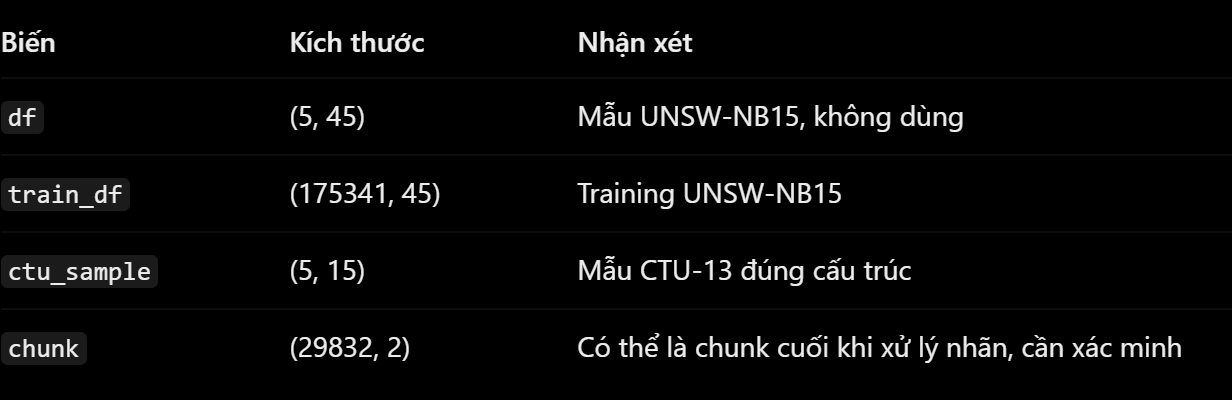

In [260]:
import pandas as pd

# Dùng đúng đường dẫn file đã sử dụng
# trong bước CTU-13 Label Grouping trước đó.
ctu_path = r"D:\suricata-ai-project\data\raw\ctu-13\capture20110815-2.binetflow"

ctu_df = pd.read_csv(ctu_path, low_memory=False)
ctu_df.columns = ctu_df.columns.str.strip()

print("=== CTU-13 DATASET ===")
print("Shape:", ctu_df.shape)
print("Columns:", ctu_df.columns.tolist())

if len(ctu_df) != 129832:
    print("WARNING: Row count differs from previous grouping!")

print("\n=== MISSING VALUES ===")
missing = ctu_df.isna().sum()
display(missing[missing > 0].to_frame("Missing"))

print("\n=== DUPLICATE ROWS ===")
print("Duplicates:", ctu_df.duplicated().sum())

print("\n=== ORIGINAL LABELS ===")
display(ctu_df["Label"].value_counts(dropna=False))

print("\n=== INVALID NUMERIC VALUES ===")
for col in ["Dur", "TotPkts", "TotBytes", "SrcBytes"]:
    if col in ctu_df.columns:
        values = pd.to_numeric(ctu_df[col], errors="coerce")
        print(
            col,
            "| Invalid:", values.isna().sum(),
            "| Negative:", (values < 0).sum()
        )

print("\n=== TIMESTAMP ===")
times = pd.to_datetime(
    ctu_df["StartTime"], errors="coerce"
)
print("Invalid timestamps:", times.isna().sum())
print("Earliest:", times.min())
print("Latest:", times.max())


=== CTU-13 DATASET ===
Shape: (129832, 15)
Columns: ['StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir', 'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes', 'Label']

=== MISSING VALUES ===


,Missing
Sport,797
Dport,377
sTos,858
dTos,6896



=== DUPLICATE ROWS ===
Duplicates: 0

=== ORIGINAL LABELS ===


Label
flow=To-Background-UDP-CVUT-DNS-Server                      50817
flow=Background-UDP-Established                             37203
flow=Background-TCP-Established                             15156
flow=Background-Established-cmpgw-CVUT                       9331
flow=Background                                              3426
                                                            ...  
flow=From-Botnet-V46-TCP-HTTP-Google-Net-Established-6          1
flow=From-Botnet-V46-TCP-CC7-Custom-Encryption                  1
flow=From-Botnet-V46-TCP-Established-HTTP-Ad-4                  1
flow=From-Botnet-V46-TCP-Established-Custom-Encryption-8        1
flow=From-Botnet-V46-TCP-Established                            1
Name: count, Length: 77, dtype: int64


=== INVALID NUMERIC VALUES ===
Dur | Invalid: 0 | Negative: 0
TotPkts | Invalid: 0 | Negative: 0
TotBytes | Invalid: 0 | Negative: 0
SrcBytes | Invalid: 0 | Negative: 0

=== TIMESTAMP ===
Invalid timestamps: 0
Earliest: 2011-08-15 16:43:20.931208
Latest: 2011-08-15 17:13:26.758894


Xác minh 77 nhãn gốc có được nhóm nhất quán thành Background, Normal và Botnet không.



Phát hiện nhãn không xác định hoặc đồng thời khớp nhiều nhóm.



Kiểm tra các giá trị thiếu có tập trung ở TCP, UDP, ICMP hay không.



Chưa thay đổi dữ liệu gốc.

In [261]:

import pandas as pd

# 1. Validate original labels
labels = ctu_df["Label"].astype("string").str.strip()

flags = pd.DataFrame({
    "Background": labels.str.contains(
        "Background", case=False, regex=False, na=False
    ),
    "Normal": labels.str.contains(
        "Normal", case=False, regex=False, na=False
    ),
    "Botnet": labels.str.contains(
        "Botnet", case=False, regex=False, na=False
    )
}, index=ctu_df.index)

match_count = flags.sum(axis=1)

print("=== LABEL VALIDATION ===")
print("Unmatched:", (match_count == 0).sum())
print("Ambiguous:", (match_count > 1).sum())

# 2. Assign only unambiguous groups
ctu_group = pd.Series(
    "Unclassified",
    index=ctu_df.index,
    name="LabelGroup"
)

for group in flags.columns:
    valid = flags[group] & (match_count == 1)
    ctu_group.loc[valid] = group

ctu_group.loc[match_count > 1] = "Ambiguous"

print("\n=== LABEL DISTRIBUTION ===")
display(ctu_group.value_counts().to_frame("Count"))

# 3. Inspect problematic labels, if any
problematic = ctu_group.isin(
    ["Unclassified", "Ambiguous"]
)

if problematic.any():
    print("\n=== PROBLEMATIC ORIGINAL LABELS ===")
    display(
        ctu_df.loc[problematic, "Label"]
        .value_counts()
        .head(20)
    )

# 4. Missing values by protocol
cols = ["Sport", "Dport", "sTos", "dTos"]

print("\n=== MISSING (%) BY PROTOCOL ===")
missing_by_proto = (
    ctu_df.groupby("Proto")[cols]
    .agg(lambda x: x.isna().mean() * 100)
    .round(2)
)
display(missing_by_proto)

# 5. Missing values by label group
print("\n=== MISSING (%) BY LABEL GROUP ===")
missing_by_group = (
    ctu_df.assign(LabelGroup=ctu_group)
    .groupby("LabelGroup")[cols]
    .agg(lambda x: x.isna().mean() * 100)
    .round(2)
)
display(missing_by_group)

print("\n=== VALIDATION ===")
if (match_count == 1).all():
    print("PASS: All records mapped unambiguously.")
else:
    print("REVIEW: Some labels require manual validation.")


=== LABEL VALIDATION ===
Unmatched: 0
Ambiguous: 0

=== LABEL DISTRIBUTION ===


,Count
LabelGroup,
Background,124252
Normal,4679
Botnet,901



=== MISSING (%) BY PROTOCOL ===


,Sport,Dport,sTos,dTos
Proto,,,,
arp,100.00,100.00,100.00,100.00
icmp,27.64,4.22,27.64,69.50
igmp,100.00,100.00,0.00,100.00
ipv6-icmp,0.00,100.00,0.00,100.00
ipx/spx,100.00,100.00,100.00,100.00
pim,100.00,100.00,0.00,100.00
rsvp,100.00,100.00,0.00,100.00
rtcp,0.00,0.00,0.00,0.00
rtp,0.00,0.00,0.00,0.00



=== MISSING (%) BY LABEL GROUP ===


,Sport,Dport,sTos,dTos
LabelGroup,,,,
Background,0.64,0.30,0.69,5.42
Botnet,0.00,0.00,0.00,16.87
Normal,0.06,0.06,0.06,0.19



=== VALIDATION ===
PASS: All records mapped unambiguously.


- Toàn bộ 129.832 bản ghi được phân vào đúng một trong ba nhóm: Background (124.252), Normal (4.679) và Botnet (901). Không có nhãn chưa phân loại hoặc khớp nhiều nhóm.
- Tuy nhiên, PASS mới chứng minh quy tắc đối sánh chuỗi hoạt động nhất quán, chưa chứng minh tất cả nhãn gốc đều chính xác về mặt an ninh mạng.
- Các kết quả đáng chú ý:
    - ARP, IGMP và một số giao thức khác: Sport, Dport thiếu 100%. Điều này có thể hợp lý vì chúng không sử dụng cổng TCP/UDP theo cách thông thường.
    - TCP: dTos thiếu 6,71%.
    - UDP: dTos thiếu 3,23%.
    - Botnet: dTos thiếu 16,87%, cao hơn mức 5,42% của Background và 0,19% của Normal.
- Điểm cuối rất đáng nghiên cứu. Nếu thay tất cả giá trị thiếu của dTos bằng 0, mô hình có thể học sự khác biệt về cách ghi nhận dữ liệu thay vì hành vi tấn công thực sự.

=> Vì vậy, chưa điền giá trị thiếu, chưa xóa bản ghi và chưa cân bằng dữ liệu.

In [262]:
import pandas as pd

# Work on a copy, preserve original dataset
audit_df = ctu_df.copy()
audit_df["LabelGroup"] = ctu_group

# 1. Protocol distribution by label
print("=== PROTOCOL DISTRIBUTION (COUNT) ===")

proto_count = pd.crosstab(
    audit_df["LabelGroup"],
    audit_df["Proto"]
)
display(proto_count)

# 2. Within-group protocol percentages
print("\n=== PROTOCOL DISTRIBUTION (%) ===")

proto_pct = (
    proto_count.div(proto_count.sum(axis=1), axis=0)
    * 100
).round(2)

display(proto_pct)

# 3. Missing dTos by group and protocol
print("\n=== MISSING dTos BY GROUP AND PROTOCOL ===")

dtos_missing = (
    audit_df.assign(dTosMissing=audit_df["dTos"].isna())
    .groupby(["LabelGroup", "Proto"])
    .agg(
        Records=("dTosMissing", "size"),
        Missing=("dTosMissing", "sum"),
        MissingPct=("dTosMissing", "mean")
    )
)

dtos_missing["MissingPct"] *= 100
display(dtos_missing.round(2))

# 4. Temporal distribution by 5-minute intervals
print("\n=== TEMPORAL DISTRIBUTION (5 MIN) ===")

timestamps = pd.to_datetime(
    audit_df["StartTime"], errors="coerce"
)

time_bins = timestamps.dt.floor("5min")

temporal_count = pd.crosstab(
    time_bins,
    audit_df["LabelGroup"]
)

display(temporal_count)

print("\n=== VALIDATION ===")
print("Total records:", proto_count.to_numpy().sum())
print("Time bins:", len(temporal_count))
print("Missing timestamps:", timestamps.isna().sum())


=== PROTOCOL DISTRIBUTION (COUNT) ===


Proto,arp,icmp,igmp,ipv6-icmp,ipx/spx,pim,rsvp,rtcp,rtp,tcp,udp
LabelGroup,,,,,,,,,,,
Background,68,2062,150,11,1,1,1,68,28,29354,92508
Botnet,0,0,0,0,0,0,0,0,0,849,52
Normal,3,0,0,0,0,0,0,0,0,1696,2980



=== PROTOCOL DISTRIBUTION (%) ===


Proto,arp,icmp,igmp,ipv6-icmp,ipx/spx,pim,rsvp,rtcp,rtp,tcp,udp
LabelGroup,,,,,,,,,,,
Background,0.05,1.66,0.12,0.01,0.0,0.0,0.0,0.05,0.02,23.62,74.45
Botnet,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.00,94.23,5.77
Normal,0.06,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.00,36.25,63.69



=== MISSING dTos BY GROUP AND PROTOCOL ===


Records  Missing  MissingPct
LabelGroup Proto                                  
Background arp             68       68      100.00
           icmp          2062     1433       69.50
           igmp           150      150      100.00
           ipv6-icmp       11       11      100.00
           ipx/spx          1        1      100.00
           pim              1        1      100.00
           rsvp             1        1      100.00
           rtcp            68        0        0.00
           rtp             28        0        0.00
           tcp          29354     1989        6.78
           udp          92508     3081        3.33
Botnet     tcp            849      149       17.55
           udp             52        3        5.77
Normal     arp              3        3      100.00
           tcp           1696        1        0.06
           udp           2980        5        0.17


=== TEMPORAL DISTRIBUTION (5 MIN) ===


LabelGroup,Background,Botnet,Normal
StartTime,,,
2011-08-15 16:40:00,10151,0,127
2011-08-15 16:45:00,22364,0,484
2011-08-15 16:50:00,19905,44,1208
2011-08-15 16:55:00,19030,146,1434
2011-08-15 17:00:00,20163,284,827
2011-08-15 17:05:00,20735,306,481
2011-08-15 17:10:00,11904,121,118



=== VALIDATION ===
Total records: 129832
Time bins: 7
Missing timestamps: 0


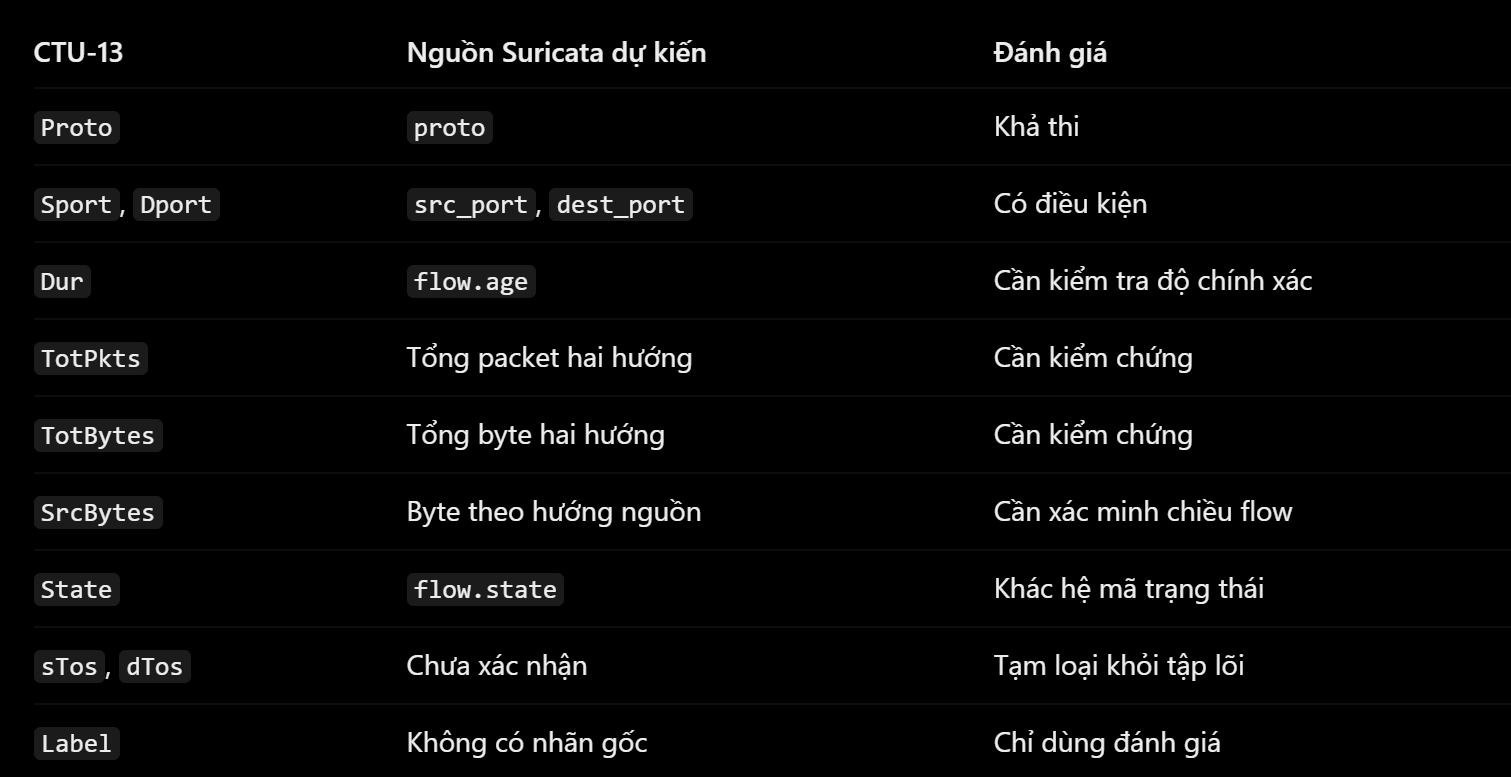

In [263]:

import json
import pandas as pd
from pathlib import Path

# Locate exported Suricata sample
paths = [
    Path("data/samples/suricata/suricata-flow-sample.json"),
    Path("../data/samples/suricata/suricata-flow-sample.json")
]

eve_path = next((p for p in paths if p.is_file()), None)

if eve_path is None:
    print("Suricata sample not found.")
    print("Check notebook working directory:")
    print(Path.cwd())
else:
    raw = eve_path.read_text(encoding="utf-8-sig")

    try:
        records = json.loads(raw)
    except json.JSONDecodeError:
        records = [
            json.loads(line)
            for line in raw.splitlines()
            if line.strip()
        ]

    if isinstance(records, dict):
        records = [records]

    flow_records = [
        r for r in records
        if isinstance(r, dict)
        and (
            r.get("event_type") == "flow"
            or (
                "event_type" not in r
                and isinstance(r.get("flow"), dict)
            )
        )
    ]

    eve_df = pd.json_normalize(flow_records)

    print("=== SURICATA FLOW SAMPLE ===")
    print("Flow records:", len(eve_df))
    print("Available fields:")
    print(eve_df.columns.tolist())

    # CTU to Suricata candidate mapping
    feature_map = {
        "Proto": ["proto"],
        "Sport": ["src_port"],
        "Dport": ["dest_port"],
        "Dur": ["flow.age"],
        "TotPkts": [
            "flow.pkts_toserver",
            "flow.pkts_toclient"
        ],
        "TotBytes": [
            "flow.bytes_toserver",
            "flow.bytes_toclient"
        ],
        "SrcBytes": [
            "flow.bytes_toserver",
            "flow.bytes_toclient"
        ],
        "State": ["flow.state"]
    }

    results = []

    for feature, required in feature_map.items():
        available = [
            col for col in required
            if col in eve_df.columns
        ]

        results.append({
            "CTU Feature": feature,
            "Required Fields": ", ".join(required),
            "Present": len(available),
            "Required": len(required),
            "Fields Available": (
                len(available) == len(required)
            )
        })

    print("\n=== FEATURE AVAILABILITY AUDIT ===")
    display(pd.DataFrame(results))


=== SURICATA FLOW SAMPLE ===
Flow records: 1
Available fields:
['timestamp', 'flow_id', 'in_iface', 'event_type', 'ip_v', 'proto', 'icmp_type', 'icmp_code', 'flow.pkts_toserver', 'flow.pkts_toclient', 'flow.bytes_toserver', 'flow.bytes_toclient', 'flow.start', 'flow.end', 'flow.age', 'flow.state', 'flow.reason', 'flow.alerted']

=== FEATURE AVAILABILITY AUDIT ===


,CTU Feature,Required Fields,Present,Required,Fields Available
0,Proto,proto,1,1,True
1,Sport,src_port,0,1,False
2,Dport,dest_port,0,1,False
3,Dur,flow.age,1,1,True
4,TotPkts,"flow.pkts_toserver, flow.pkts_toclient",2,2,True
5,TotBytes,"flow.bytes_toserver, flow.bytes_toclient",2,2,True
6,SrcBytes,"flow.bytes_toserver, flow.bytes_toclient",2,2,True
7,State,flow.state,1,1,True


In [264]:

import pandas as pd

# Preserve original CTU-13 data
ctu_audit = ctu_df.copy()
ctu_audit["LabelGroup"] = ctu_group

# Focus on TCP/UDP, matching the verified
# Suricata protocol coverage.
ctu_audit = ctu_audit[
    ctu_audit["Proto"].astype(str).str.lower()
    .isin(["tcp", "udp"])
].copy()

numeric_cols = [
    "Dur", "TotPkts", "TotBytes", "SrcBytes"
]

for col in numeric_cols:
    ctu_audit[col] = pd.to_numeric(
        ctu_audit[col], errors="coerce"
    )

print("=== TCP/UDP DATASET OVERVIEW ===")
print("Records:", len(ctu_audit))
display(ctu_audit["LabelGroup"].value_counts())

print("\n=== FEATURE CONSISTENCY CHECK ===")

checks = pd.DataFrame({
    "Zero duration": ctu_audit["Dur"] == 0,
    "Zero packets": ctu_audit["TotPkts"] == 0,
    "Zero bytes": ctu_audit["TotBytes"] == 0,
    "SrcBytes > TotBytes": (
        ctu_audit["SrcBytes"] > ctu_audit["TotBytes"]
    ),
    "Zero duration with packets": (
        (ctu_audit["Dur"] == 0) &
        (ctu_audit["TotPkts"] > 0)
    )
}, index=ctu_audit.index)

report = pd.DataFrame({
    "Count": checks.sum(),
    "Percent": (
        checks.mean() * 100
    ).round(3)
})

display(report)

print("\n=== FEATURE DISTRIBUTION BY LABEL ===")

for col in numeric_cols:
    print(f"\nFeature: {col}")

    stats = (
        ctu_audit.groupby("LabelGroup")[col]
        .agg(
            Count="count",
            Median="median",
            Mean="mean",
            Max="max"
        )
        .round(3)
    )

    display(stats)

print("\n=== VALIDATION ===")

if ctu_audit[numeric_cols].isna().any().any():
    print("REVIEW: Invalid or missing numeric features.")
else:
    print("PASS: Core numeric features are present.")

print("Original CTU-13 records:", len(ctu_df))
print("TCP/UDP records:", len(ctu_audit))
print("Excluded non-TCP/UDP:", len(ctu_df) - len(ctu_audit))


=== TCP/UDP DATASET OVERVIEW ===
Records: 127439


LabelGroup
Background    121862
Normal          4676
Botnet           901
Name: count, dtype: int64


=== FEATURE CONSISTENCY CHECK ===


,Count,Percent
Zero duration,1020,0.8
Zero packets,0,0.0
Zero bytes,0,0.0
SrcBytes > TotBytes,0,0.0
Zero duration with packets,1020,0.8



=== FEATURE DISTRIBUTION BY LABEL ===

Feature: Dur


,Count,Median,Mean,Max
LabelGroup,,,,
Background,121862,0.001,78.156,1805.828
Botnet,901,1.593,6.489,1139.729
Normal,4676,0.002,27.803,1805.375


... (3 outputs left out)

,Count,Median,Mean,Max
LabelGroup,,,,
Background,121862,265.0,28301.020,853704136
Botnet,901,366.0,22660.565,615599
Normal,4676,396.0,58348.089,137416417



Feature: SrcBytes


,Count,Median,Mean,Max
LabelGroup,,,,
Background,121862,81.0,3980.623,85080318
Botnet,901,186.0,10965.527,600198
Normal,4676,81.0,34906.984,136546777



=== VALIDATION ===
PASS: Core numeric features are present.
Original CTU-13 records: 129832
TCP/UDP records: 127439
Excluded non-TCP/UDP: 2393


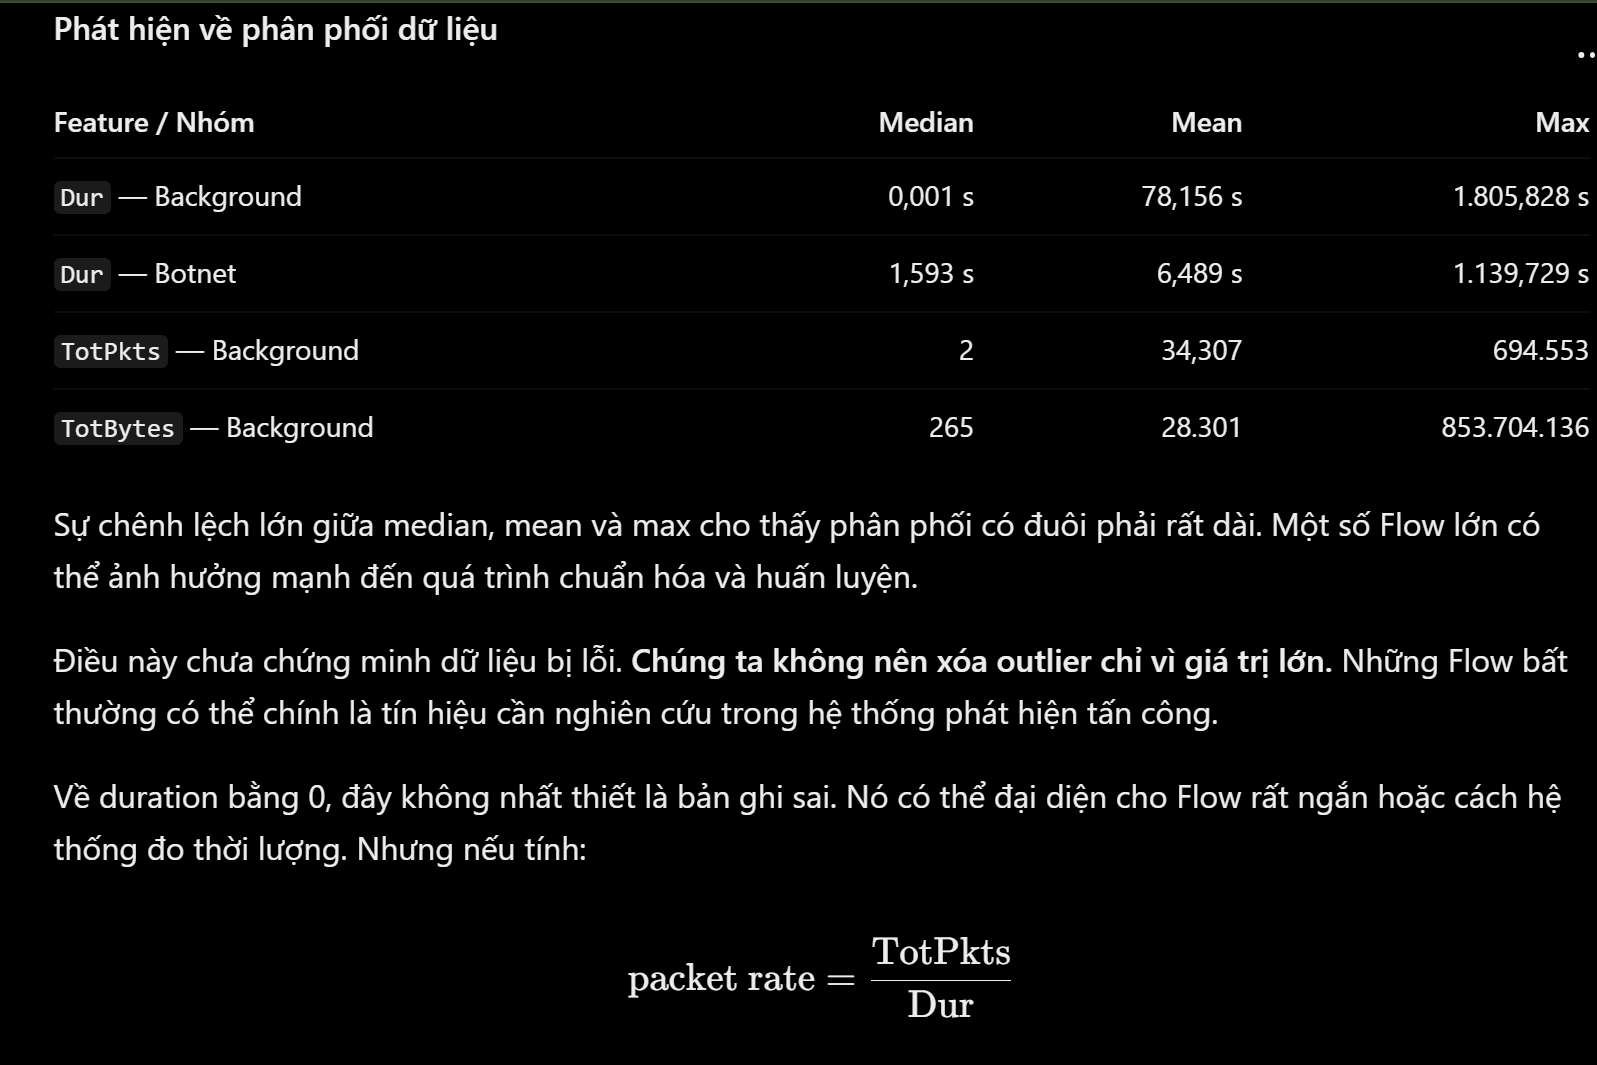

In [265]:

import numpy as np
import pandas as pd

# Preserve original CTU-13
mask = ctu_df["Proto"].str.lower().isin(["tcp", "udp"])

ctu_v1 = ctu_df.loc[
    mask,
    [
        "StartTime", "SrcAddr", "DstAddr",
        "Proto", "Dur", "TotPkts", "TotBytes"
    ]
].copy()

ctu_v1["LabelGroup"] = ctu_group.loc[ctu_v1.index]

ctu_v1 = ctu_v1.rename(columns={
    "Proto": "protocol",
    "Dur": "duration_s",
    "TotPkts": "total_packets",
    "TotBytes": "total_bytes"
})

ctu_v1["protocol"] = ctu_v1["protocol"].str.lower()

# Candidate model features
feature_columns = [
    "protocol",
    "duration_s",
    "total_packets",
    "total_bytes"
]

numeric_features = [
    "duration_s",
    "total_packets",
    "total_bytes"
]

print("=== FEATURE SCHEMA V1 ===")
print("Records:", len(ctu_v1))
print("Model features:", feature_columns)
display(ctu_v1[feature_columns].dtypes.to_frame("Dtype"))

print("\n=== LABEL DISTRIBUTION ===")
display(ctu_v1["LabelGroup"].value_counts())

# Validate values without modifying them
print("\n=== FEATURE VALIDATION ===")

X_numeric = ctu_v1[numeric_features].astype(float)

print("Missing:", int(X_numeric.isna().sum().sum()))
print("Non-finite:", int((~np.isfinite(X_numeric)).sum().sum()))
print("Negative:", int((X_numeric < 0).sum().sum()))

print("\n=== QUANTILE ANALYSIS BY LABEL ===")

for feature in numeric_features:
    print(f"\nFeature: {feature}")

    quantiles = (
        ctu_v1.groupby("LabelGroup")[feature]
        .quantile([0.50, 0.90, 0.99, 0.999])
        .unstack()
    )

    quantiles.columns = ["P50", "P90", "P99", "P99.9"]
    display(quantiles.round(3))

print("\n=== ZERO DURATION BY LABEL ===")

zero_duration = (
    ctu_v1.assign(
        IsZero=ctu_v1["duration_s"].eq(0)
    )
    .groupby("LabelGroup")["IsZero"]
    .agg(["sum", "count", "mean"])
)

zero_duration["mean"] *= 100
zero_duration.columns = [
    "ZeroCount", "Total", "ZeroPercent"
]

display(zero_duration.round(3))

print("\n=== STATUS ===")
print("Original dataset preserved.")
print("No rows removed from original.")
print("No imputation or scaling applied.")
print("No train/test split performed.")


=== FEATURE SCHEMA V1 ===
Records: 127439
Model features: ['protocol', 'duration_s', 'total_packets', 'total_bytes']


,Dtype
protocol,str
duration_s,float64
total_packets,int64
total_bytes,int64



=== LABEL DISTRIBUTION ===


LabelGroup
Background    121862
Normal          4676
Botnet           901
Name: count, dtype: int64


=== FEATURE VALIDATION ===
Missing: 0
Non-finite: 0
Negative: 0

=== QUANTILE ANALYSIS BY LABEL ===

Feature: duration_s


,P50,P90,P99,P99.9
LabelGroup,,,,
Background,0.001,88.042,1572.949,1786.375
Botnet,1.593,9.012,41.124,564.185
Normal,0.002,35.971,434.066,1738.481


... (3 outputs left out)

,P50,P90,P99,P99.9
LabelGroup,,,,
Background,265.0,4241.9,95769.97,1.840099e+06
Botnet,366.0,100495.0,555439.00,6.143831e+05
Normal,396.0,6444.0,188482.50,1.109071e+07



=== ZERO DURATION BY LABEL ===


,ZeroCount,Total,ZeroPercent
LabelGroup,,,
Background,1015,121862,0.833
Botnet,4,901,0.444
Normal,1,4676,0.021



=== STATUS ===
Original dataset preserved.
No rows removed from original.
No imputation or scaling applied.
No train/test split performed.
